# 02 · Modelo supervisado — Forecast de demanda horaria del MEM

**Proyecto:** Forecast de demanda eléctrica del Mercado Eléctrico Mayorista (MEM) argentino.

**Etapa:** Pre-entrega 3 — modelo supervisado de punta a punta: desde la preparación de los datos hasta la evaluación y la selección del modelo, evitando el overfitting con optimización de hiperparámetros.
Ampliado en la pre-entrega 4 (secciones 11.3 a 11.5) y revisado antes de la entrega final (ver la última tabla).

## Objetivo

Predecir la **demanda eléctrica horaria del MEM (MWh)** del día siguiente a partir de variables de **calendario** y **temperatura**. Se resuelven dos problemas:

1. **Regresión:** cuántos MWh se van a demandar en cada hora.
2. **Clasificación:** si una hora va a ser una **hora de demanda alta** (dentro del 10 % de mayor demanda histórica).

## Decisiones de diseño

| Decisión | Elección | Por qué |
|---|---|---|
| Momento de emisión | El pronóstico del día D se emite el **día D-1 a las 12:00** (supuesto) | Todas las horas de D se predicen con la información disponible en ese único momento, como en una programación del día siguiente. |
| Temperatura | Horaria, coordenadas de Aeroparque. **Observada** para entrenar; en el test, **la corrida del modelo ECMWF disponible al emitir** | GBA + Buenos Aires son ~50 % de la demanda. Al pronosticar solo se conoce el pronóstico del tiempo, no la temperatura que va a hacer. |
| Variables | Calendario + temperatura, **sin demanda pasada** en el modelo principal | El objetivo es explicar y anticipar la demanda por calendario y clima. En la sección 13 se prueba aparte una variante con demanda reciente. |
| Split | Train 2021–2024, test ene-2025 → jul-2026 | Siempre por tiempo: se entrena con el pasado y se evalúa con el futuro. El test tiene un año completo, con verano e invierno. |
| Referencias | Perfil promedio y misma hora de la semana anterior | Un modelo de machine learning tiene que ganarles a reglas simples para justificarse. |
| Métrica principal | MAPE, junto con WAPE | Error porcentual, estándar en la industria eléctrica y fácil de comunicar. |

## Cambios a partir de la devolución de la pre-entrega 2

| Observación del profesor | Cómo se resolvió |
|---|---|
| Al pronosticar se dispone de la temperatura **prevista**, no de la observada: cuidado con la fuga de información | El test se evalúa con el pronóstico del tiempo **disponible al momento de emitir** (sección 4). También se muestra el error con la temperatura observada, para medir cuánto cuesta el error del pronóstico del tiempo (sección 11). |
| Definir un modelo base sencillo, como la demanda de la misma hora de la semana anterior | Se agregó esa referencia junto al perfil promedio (sección 6). |
| Separar entrenamiento y prueba respetando el orden temporal | Train 2021–2024 y test 2025 → jul-2026, con validación cruzada temporal dentro de train (sección 4). |

## Mejoras de la pre-entrega 4

| Mejora | Por qué | Sección |
|---|---|---|
| **WAPE** junto al MAPE | En el despacho los desvíos se miden en porcentaje sobre la energía programada; el WAPE pondera más las horas de mayor demanda. Lo sugirió la devolución de la pre-entrega 3. | 5 |
| **Días de calor extremo** | Cuantificar cuánto peor predice el modelo en los días más calurosos. | 11.3 |
| **Reentrenamiento mensual** | El modelo fijo subestimaba cada vez más. Se simula reentrenarlo todos los meses. | 11.4 |
| **Intervalos de predicción** | Dar una banda ("entre X e Y MW con 80 % de probabilidad") en lugar de un solo número, para cuantificar la incertidumbre. | 11.5 |

## Revisión antes de la entrega final

Una revisión crítica del trabajo encontró errores y afirmaciones demasiado fuertes. Se corrigieron así:

| Hallazgo | Corrección | Dónde |
|---|---|---|
| El pronóstico del tiempo del test era "el de 24 h antes de **cada** hora": cada hora usaba una corrida distinta, algunas posteriores al momento en que se emitiría el pronóstico | Se fija un momento de emisión (D-1 12:00) y se usa **una sola corrida** del modelo ECMWF para todas las horas del día | Sección 4 y `src/descargar_temperatura_pronosticada.py` |
| Cuatro días con el tipo de día mal etiquetado en la planilla de CAMMESA (Jueves y Viernes Santo 2023, feriados puente del 23/03/2026 y del 10/07/2026) | El script de la serie compara el tipo de día con las fuentes de CAMMESA que distinguen 7 tipos y corrige las diferencias | `src/descargar_demanda_mem.py` |
| El Gradient Boosting separaba internamente una validación **al azar** (`early_stopping`) | Se desactiva: toda la validación respeta el orden del tiempo | Sección 9 |
| El "+4 % de crecimiento en 2026" comparaba enero–julio contra un año completo | Se comparan períodos equivalentes | Sección 11.1 |
| La cobertura global de los intervalos escondía meses con mucha menos cobertura | Cobertura por mes y *interval score* | Sección 11.5 |
| El ancho de la banda se presentaba como "la reserva necesaria" | Se corrige: mide incertidumbre de la demanda, no la reserva del sistema | Sección 11.5 |
| "WAPE ≈ MAPE" se usaba para afirmar que el modelo predice bien los picos | Se mide el error en las horas de demanda alta y en el máximo de cada día | Sección 11.7 |
| No se analizaba el error según la anticipación | Error por horas desde la emisión | Sección 11.6 |
| La demanda reciente quedaba descartada sin medir cuánto aporta | Variante predictiva con rezagos disponibles al emitir, elegidos con validación temporal | Sección 13 |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestClassifier, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, average_precision_score, classification_report, f1_score,
    mean_absolute_error, mean_absolute_percentage_error, precision_score, recall_score,
    roc_auc_score, root_mean_squared_error,
)
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit, cross_val_score, validation_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = BASE / "data" / "processed"
FIG = BASE / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# semilla fija para que los resultados sean reproducibles
SEMILLA = 42


def guardar(nombre):
    """Muestra el gráfico actual y lo guarda en reports/figures."""
    plt.tight_layout()
    plt.savefig(FIG / f"02_{nombre}.png", bbox_inches="tight")
    plt.show()

## 1. Carga y unión de los datos

- `demanda_horaria_mem.csv`: serie horaria del MEM construida y validada en la pre-entrega 2 (48.912 horas, sin huecos).
- `temperatura_horaria_ba.csv`: temperatura horaria **observada** de Buenos Aires (reanálisis ERA5), descargada de Open-Meteo con `src/descargar_temperatura.py`.
- `temperatura_pronosticada_ba.csv`: para cada día del test, la temperatura horaria que pronosticaba el modelo **ECMWF** en la corrida disponible al momento de emitir (D-1 12:00). Descargada de Open-Meteo con `src/descargar_temperatura_pronosticada.py`.

In [2]:
demanda = pd.read_csv(DATA / "demanda_horaria_mem.csv", parse_dates=["timestamp"])
temperatura = pd.read_csv(DATA / "temperatura_horaria_ba.csv", parse_dates=["timestamp"])
# pronóstico del tiempo disponible al emitir: 36 horas por día del test (de D-1 12:00 a D 23:00), de una sola corrida
pronostico = pd.read_csv(DATA / "temperatura_pronosticada_ba.csv", parse_dates=["timestamp", "dia_objetivo"])

# validate="one_to_one" hace fallar el merge si algún timestamp estuviera repetido en alguna de las dos tablas
df = demanda.merge(temperatura, on="timestamp", how="left", validate="one_to_one")

print(f"Filas: {len(df):,} | {df.timestamp.min()} -> {df.timestamp.max()}")
print(f"Horas sin temperatura: {df.temperatura_c.isna().sum()}")
df[["timestamp", "demanda_mwh", "tipo_dia", "temperatura_c"]].head()

Filas: 48,912 | 2021-01-01 00:00:00 -> 2026-07-31 23:00:00
Horas sin temperatura: 0


,timestamp,demanda_mwh,tipo_dia,temperatura_c
0,2021-01-01 00:00:00,12329.594,no_habil,21.8
1,2021-01-01 01:00:00,12097.918,no_habil,21.6
2,2021-01-01 02:00:00,11805.739,no_habil,21.4
3,2021-01-01 03:00:00,11447.416,no_habil,20.9
4,2021-01-01 04:00:00,11143.879,no_habil,20.4


## 2. Exploración orientada al modelo

En el EDA vimos la relación demanda–temperatura con datos **diarios**. Ahora la miramos con la temperatura **horaria** y elegimos cómo convertirla en variables útiles para el modelo.

Para no tomar decisiones mirando el período de test, esta exploración se hace **solo con los datos de entrenamiento** (hasta 2024).

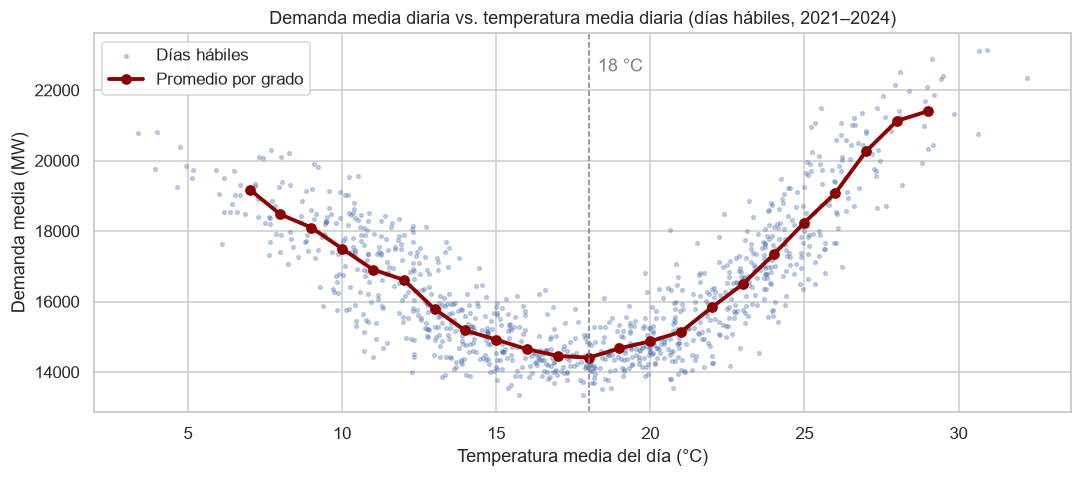

Temperatura con menor demanda promedio: 18.0 °C


In [3]:
FIN_TRAIN = pd.Timestamp("2025-01-01")
en_train = df["timestamp"] < FIN_TRAIN

# demanda media diaria vs temperatura media diaria, en días hábiles del período de entrenamiento
diario = (
    df[en_train]
    .groupby(df.timestamp.dt.normalize())
    .agg(demanda=("demanda_mwh", "mean"), temperatura=("temperatura_c", "mean"), tipo_dia=("tipo_dia", "first"))
)
habiles = diario[diario.tipo_dia == "habil"]
por_grado = habiles.groupby(habiles.temperatura.round())["demanda"].agg(["mean", "count"])
por_grado = por_grado[por_grado["count"] >= 10]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(habiles.temperatura, habiles.demanda, s=6, alpha=0.3, label="Días hábiles")
ax.plot(por_grado.index, por_grado["mean"], color="darkred", lw=2.5, marker="o", label="Promedio por grado")
ax.axvline(18, color="gray", ls="--", lw=1)
ax.text(18.3, ax.get_ylim()[1] * 0.97, "18 °C", color="gray", va="top")
ax.set(title="Demanda media diaria vs. temperatura media diaria (días hábiles, 2021–2024)",
       xlabel="Temperatura media del día (°C)", ylabel="Demanda media (MW)")
ax.legend()
guardar("demanda_vs_temperatura_train")

print("Temperatura con menor demanda promedio:", por_grado["mean"].idxmin(), "°C")

La U se confirma con la temperatura horaria de Open-Meteo: la demanda es mínima alrededor de los **18 °C** y sube hacia los dos lados. Esa temperatura es la "zona de confort": no se prende ni la calefacción ni el aire acondicionado.

Eso define cómo transformar la temperatura. Una regresión lineal con la temperatura "cruda" ajustaría una recta, y una recta no puede bajar y después subir. Por eso se usan los **grados-día**, una convención de la industria energética:

- **Grados de calefacción (`hdd`):** cuántos grados por debajo de 18 °C está la temperatura. Vale 0 si hace más de 18 °C.
- **Grados de refrigeración (`cdd`):** cuántos grados por encima de 18 °C. Vale 0 si hace menos.

Así cada rama de la U se vuelve una relación lineal que hasta la regresión lineal puede aprender.

## 3. Feature engineering

| Variable | Qué es | Por qué |
|---|---|---|
| `hora` | Hora del día (0–23) | La curva de carga diaria: valle de madrugada, picos de tarde o noche. |
| `dia_semana` | 0 = lunes … 6 = domingo | El perfil semanal visto en el EDA. |
| `mes` | 1–12 | La estacionalidad anual y la hora del pico, que cambia según la estación. |
| `es_habil` | 1 si CAMMESA clasifica el día como hábil | Captura **feriados**, que el día de la semana solo no ve. |
| `temperatura_c` | Temperatura de esa hora | El efecto inmediato del clima. |
| `temp_24h` | Promedio de las últimas 24 h | **Inercia térmica**: los edificios tardan en calentarse o enfriarse, así que la demanda responde al calor o frío acumulado, no solo al de esa hora. |
| `hdd`, `cdd` | Grados de calefacción y refrigeración sobre `temp_24h`, base 18 °C | Las dos ramas de la U, como se explicó arriba. |

Todas las variables se pueden conocer **antes** de la hora a predecir: el calendario se sabe de antemano y la temperatura sale del pronóstico del tiempo. Ninguna usa la demanda

Como las variables climáticas se calculan igual con la temperatura observada (para entrenar) y con la pronosticada (para el test), se arman con una función.

In [4]:
TEMP_CONFORT = 18


def variables_temperatura(temperatura):
    """Arma las 4 variables climáticas del modelo a partir de una serie horaria de temperatura."""
    # promedio móvil de las últimas 24 horas (incluida la actual); las primeras horas de la serie usan las que haya
    temp_24h = temperatura.rolling(24, min_periods=1).mean()
    return pd.DataFrame({
        "temperatura_c": temperatura,
        "temp_24h": temp_24h,
        "hdd": (TEMP_CONFORT - temp_24h).clip(lower=0),
        "cdd": (temp_24h - TEMP_CONFORT).clip(lower=0),
    })


df["hora"] = df.timestamp.dt.hour
df["dia_semana"] = df.timestamp.dt.dayofweek
df["mes"] = df.timestamp.dt.month
df["es_habil"] = (df["tipo_dia"] == "habil").astype(int)

clima = variables_temperatura(df["temperatura_c"])
df[clima.columns] = clima

CATEGORICAS = ["hora", "dia_semana", "mes"]
CLIMATICAS = ["temperatura_c", "temp_24h", "hdd", "cdd"]
NUMERICAS = ["es_habil"] + CLIMATICAS
VARIABLES = CATEGORICAS + NUMERICAS

df[["timestamp"] + VARIABLES + ["demanda_mwh"]].head()

,timestamp,hora,dia_semana,mes,es_habil,temperatura_c,temp_24h,hdd,cdd,demanda_mwh
0,2021-01-01 00:00:00,0,4,1,0,21.8,21.800,0.0,3.800,12329.594
1,2021-01-01 01:00:00,1,4,1,0,21.6,21.700,0.0,3.700,12097.918
2,2021-01-01 02:00:00,2,4,1,0,21.4,21.600,0.0,3.600,11805.739
3,2021-01-01 03:00:00,3,4,1,0,20.9,21.425,0.0,3.425,11447.416
4,2021-01-01 04:00:00,4,4,1,0,20.4,21.220,0.0,3.220,11143.879


In [5]:
# correlación de cada variable numérica con la demanda (solo train)
df.loc[en_train, NUMERICAS + ["demanda_mwh"]].corr()["demanda_mwh"].drop("demanda_mwh").round(2).sort_values()

temp_24h         0.10
hdd              0.18
temperatura_c    0.22
es_habil         0.32
cdd              0.38
Name: demanda_mwh, dtype: float64

La correlación lineal es una medida limitada para una relación en U, pero sirve para comparar:

- `cdd` (0,38) correlaciona más que la temperatura cruda (0,22): al separar el calor del frío, la rama de verano se vuelve una relación lineal.
- `hdd` correlaciona menos (0,18) porque el frío mueve menos la demanda que el calor. En el gráfico anterior, de 18 °C a 28 °C la demanda sube unos 6.700 MW (~670 MW por grado), y de 18 °C a 7 °C sube unos 4.800 MW (~430 MW por grado).

La prueba de fuego de estas variables no es la correlación, sino si mejoran el modelo.

## 4. Separación temporal en entrenamiento y test

En series temporales **no se puede separar al azar**. Si una hora de marzo de 2025 quedara en train y la siguiente en test, el modelo "conocería el futuro" y el error de test sería engañosamente bajo. Se entrena con el pasado y se evalúa con el futuro, igual que pasaría en la operación real. Esta fue una de las observaciones de la devolución de la pre-entrega 2.

In [6]:
X = df[VARIABLES]
y = df["demanda_mwh"]
X_train, X_test = X[en_train], X[~en_train]
y_train, y_test = y[en_train], y[~en_train]
t_test = df.loc[~en_train, "timestamp"]

print(f"Train: {len(X_train):,} horas ({df.timestamp[en_train].min().date()} -> {df.timestamp[en_train].max().date()})")
print(f"Test:  {len(X_test):,} horas ({t_test.min().date()} -> {t_test.max().date()})")
print(f"Proporción de test: {len(X_test) / len(X):.0%}")

Train: 35,064 horas (2021-01-01 -> 2024-12-31)
Test:  13,848 horas (2025-01-01 -> 2026-07-31)
Proporción de test: 28%


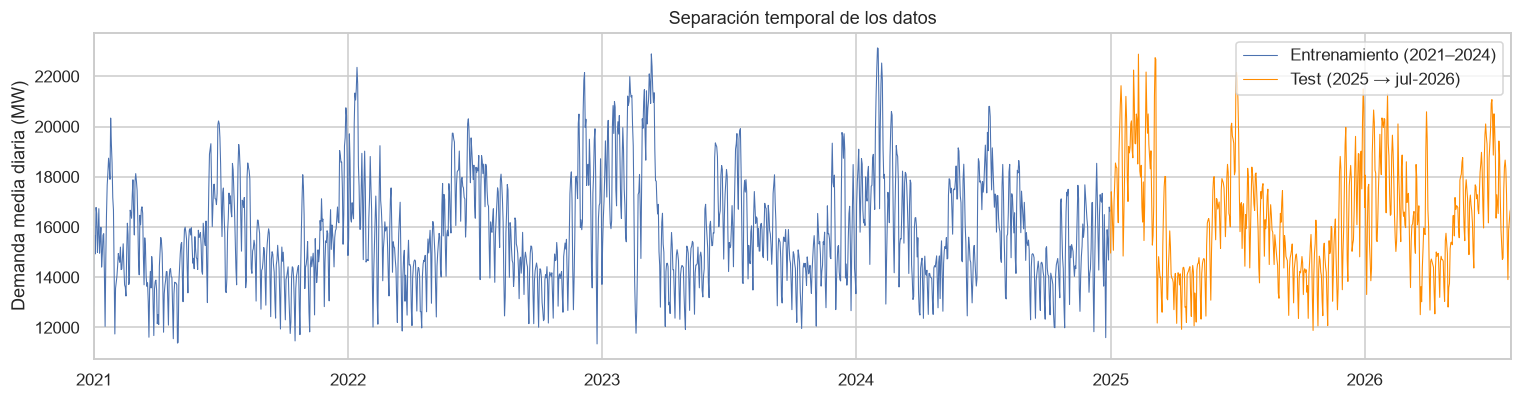

In [7]:
fig, ax = plt.subplots(figsize=(14, 3.8))
serie = df.set_index("timestamp")["demanda_mwh"].resample("D").mean()
serie[serie.index < FIN_TRAIN].plot(ax=ax, lw=0.7, label="Entrenamiento (2021–2024)")
serie[serie.index >= FIN_TRAIN].plot(ax=ax, lw=0.7, color="darkorange", label="Test (2025 → jul-2026)")
ax.set(title="Separación temporal de los datos", ylabel="Demanda media diaria (MW)", xlabel="")
ax.legend()
guardar("split_temporal")

### Temperatura en el test: la que se conocía al emitir

Si el test se evalúa con la temperatura que **efectivamente hizo**, se está suponiendo un pronóstico del tiempo perfecto. Es una **fuga de información**: el modelo usaría un dato que en la operación todavía no existe, y el error de test saldría optimista.

Para que el test sea realista hay que definir **cuándo** se emite el pronóstico y usar solo lo que se conocía en ese momento:

- **Emisión:** el pronóstico del día D se emite el día D-1 a las **12:00** (hora local). Es un supuesto razonable para la programación del día siguiente, no el horario oficial de CAMMESA.
- **Pronóstico del tiempo:** la última corrida del modelo **ECMWF IFS** publicada antes de la emisión: la de las 06 UTC de D-1 (03:00 hora local), que se publica entre 4 y 6 horas después. Se usa **la misma corrida para las 24 horas** de D, con 12 a 35 horas de anticipación desde la emisión. Fuente: Open-Meteo, *Single Runs API*.
- **Promedio de 24 h (`temp_24h`):** para las primeras horas de D, la ventana incluye horas de D-1. Antes de la emisión se usa la temperatura **observada**, que ya se conocía, y después, la **pronosticada**.

El **entrenamiento** sigue usando la temperatura observada: así el modelo aprende la relación real entre clima y demanda, sin el ruido del error de pronóstico. Es la práctica habitual. Además, el archivo de corridas de ECMWF empieza en marzo de 2024.

In [8]:
# temperatura observada: hasta el momento de emitir ya se conoce
obs = df.set_index("timestamp")["temperatura_c"]

partes = []
for dia, pron_dia in pronostico.groupby("dia_objetivo"):
    pron_dia = pron_dia.set_index("timestamp")
    emision = pron_dia.index.min()                                                    # D-1 12:00
    conocido = obs[emision - pd.Timedelta(hours=12): emision - pd.Timedelta(hours=1)]  # D-1 00:00 a 11:00, observado
    serie = pd.concat([conocido, pron_dia["temperatura_pron_c"]])                     # 48 horas: D-1 00:00 -> D 23:00
    clima_dia = variables_temperatura(serie).loc[dia:]                                # solo las 24 horas de D
    clima_dia["horas_desde_emision"] = pron_dia.loc[dia:, "horas_desde_emision"]
    partes.append(clima_dia)
clima_pron = pd.concat(partes)
assert clima_pron.index.equals(pd.DatetimeIndex(t_test.values)), "el pronóstico no cubre exactamente las horas del test"

# X_test_pron: mismas variables de calendario que X_test, con el clima que se conocía al emitir
X_test_pron = X_test.copy()
X_test_pron[CLIMATICAS] = clima_pron[CLIMATICAS].values
horizonte = pd.Series(clima_pron["horas_desde_emision"].values, index=t_test.values)   # 12 a 35 h

# ¿qué tan bueno es el pronóstico del tiempo? error de la temperatura pronosticada contra la observada
error_temp = pd.Series(X_test_pron["temperatura_c"].values - X_test["temperatura_c"].values, index=t_test.values)
print("Corridas usadas (hora UTC):", pronostico.drop_duplicates("dia_objetivo")["corrida_utc"].str[-5:].value_counts().to_dict())
print(f"Error del pronóstico de temperatura en el test: MAE {error_temp.abs().mean():.2f} °C | "
      f"sesgo {error_temp.mean():+.2f} °C | 95 % de las horas con error menor a {error_temp.abs().quantile(0.95):.1f} °C")

Corridas usadas (hora UTC): {'06:00': 577}
Error del pronóstico de temperatura en el test: MAE 0.72 °C | sesgo -0.05 °C | 95 % de las horas con error menor a 2.2 °C


### Validación cruzada temporal

Para elegir hiperparámetros sin tocar el test se usa **validación cruzada temporal** (`TimeSeriesSplit`) dentro del período de entrenamiento: se entrena con un bloque inicial y se valida con el bloque siguiente, y el bloque de entrenamiento va creciendo en cada vuelta. Así la validación respeta el orden del tiempo igual que el split final.

El **test se usa una sola vez**, al final, para medir los modelos ya elegidos.

In [9]:
cv_temporal = TimeSeriesSplit(n_splits=5)

for i, (idx_tr, idx_val) in enumerate(cv_temporal.split(X_train), start=1):
    t = df.loc[en_train, "timestamp"]
    print(f"Fold {i}: entrena {t.iloc[idx_tr[0]].date()} -> {t.iloc[idx_tr[-1]].date()} | "
          f"valida {t.iloc[idx_val[0]].date()} -> {t.iloc[idx_val[-1]].date()}")

Fold 1: entrena 2021-01-01 -> 2021-09-01 | valida 2021-09-01 -> 2022-05-02
Fold 2: entrena 2021-01-01 -> 2022-05-02 | valida 2022-05-03 -> 2023-01-01
Fold 3: entrena 2021-01-01 -> 2023-01-01 | valida 2023-01-01 -> 2023-09-01
Fold 4: entrena 2021-01-01 -> 2023-09-01 | valida 2023-09-02 -> 2024-05-02
Fold 5: entrena 2021-01-01 -> 2024-05-02 | valida 2024-05-02 -> 2024-12-31


## 5. Métricas

- **MAPE** (error porcentual absoluto medio): en promedio, en qué porcentaje se equivoca el modelo. Es la métrica principal: es la que usa la industria y se entiende sin conocer la escala ("se equivoca un 4 %").
- **RMSE** (raíz del error cuadrático medio, en MWh): penaliza más los errores grandes. Importa porque un error grande en una hora pico es el más caro para el operador.
- **MAE** (error absoluto medio, en MWh): el error típico en unidades físicas.
- **WAPE** (error porcentual absoluto ponderado): la suma de todos los errores dividida por la suma de toda la demanda. A diferencia del MAPE, que promedia el porcentaje de cada hora y les da a todas el mismo peso, el WAPE pondera por la demanda: un error en una hora pico de 25.000 MW pesa más que uno en la madrugada. Es la forma de medir el desvío sobre la energía programada, como se evalúa en el despacho.

MAPE no tiene el problema de dividir por cero, porque la demanda nunca baja de ~9.000 MW.

In [10]:
def evaluar(nombre, y_real, y_pred):
    """Devuelve las métricas de regresión de un modelo como diccionario."""
    return {
        "modelo": nombre,
        "MAPE_%": round(mean_absolute_percentage_error(y_real, y_pred) * 100, 2),
        # WAPE: suma de errores absolutos sobre suma de la demanda real
        "WAPE_%": round(np.abs(np.asarray(y_real) - np.asarray(y_pred)).sum() / np.asarray(y_real).sum() * 100, 2),
        "RMSE_MWh": round(root_mean_squared_error(y_real, y_pred)),
        "MAE_MWh": round(mean_absolute_error(y_real, y_pred)),
        "sesgo_MWh": round((np.asarray(y_real) - np.asarray(y_pred)).mean()),  # > 0: el modelo subestima en promedio
    }

## 6. Referencias ingenuas

Antes de cualquier modelo hace falta un piso: si un modelo de machine learning no le gana a una regla simple, no aporta nada. Se usan dos reglas:

1. **Perfil promedio:** predecir el promedio histórico de esa hora, en ese mes y en ese tipo de día (hábil o no). Es lo que haría alguien con una planilla de cálculo.
2. **Misma hora de la semana anterior:** predecir que la demanda va a ser igual a la de hace exactamente 7 días (168 horas). Es la referencia que sugirió el profesor y es exigente: copia el día de la semana y ya trae incorporado el nivel reciente de la demanda, incluida la tendencia de crecimiento. No tiene fuga de información: al pronosticar las próximas 24 h, la demanda de hace una semana ya se conoce.

Ninguna de las dos usa temperatura, así que no cambian entre temperatura observada y pronosticada.

In [11]:
# referencia 1: perfil promedio por mes, hora y tipo de día, calculado solo con train
perfil = df[en_train].groupby(["mes", "hora", "es_habil"])["demanda_mwh"].mean().rename("pred")
pred_perfil = df.loc[~en_train].join(perfil, on=["mes", "hora", "es_habil"])["pred"]

# referencia 2: la demanda de la misma hora 168 h (una semana) antes.
# En la primera semana del test toma la última semana de 2024, que también se conoce de antemano.
pred_semana_anterior = df["demanda_mwh"].shift(168)[~en_train]

resultados = [
    evaluar("Referencia: perfil promedio", y_test, pred_perfil),
    evaluar("Referencia: misma hora semana anterior", y_test, pred_semana_anterior),
]
pd.DataFrame(resultados)

,modelo,MAPE_%,WAPE_%,RMSE_MWh,MAE_MWh,sesgo_MWh
0,Referencia: perfil promedio,7.57,7.85,1724,1284,423
1,Referencia: misma hora semana anterior,9.12,9.22,2097,1509,9


La referencia "misma hora de la semana anterior" no tiene sesgo, porque copia el nivel reciente de la demanda, pero se equivoca más que el perfil promedio (9,1 % contra 7,6 %). Copia una sola semana, con su clima y sus particularidades:

- Si la semana pasada hizo calor y esta hace fresco, arrastra todo ese error. Es la razón principal, porque la demanda depende mucho de la temperatura.
- Los feriados le pegan doble: el día del feriado predice demanda de día hábil, y una semana después predice demanda de feriado para un día normal.

El perfil promedio, en cambio, suaviza el clima al promediar varios años. Las dos referencias marcan el piso que los modelos tienen que superar.

## 7. Baseline: Regresión Lineal

La regresión lineal es el modelo más simple e interpretable. Para que funcione hay que preparar las variables:

- `hora`, `dia_semana` y `mes` se pasan con **one-hot encoding** (una columna 0/1 por cada valor). Si se pasara `hora` como número, el modelo asumiría que la demanda sube o baja en línea recta de la hora 0 a la 23, y la curva diaria no es así.
- Las variables de temperatura entran como números. Gracias a `hdd` y `cdd`, la U ya está "linealizada".

El preprocesamiento va dentro de un **pipeline**, así se ajusta solo con los datos de entrenamiento de cada fold y no se filtra información del test.

In [12]:
preprocesamiento_lineal = ColumnTransformer(
    [("one_hot", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS)],
    remainder="passthrough",
)
modelo_lineal = make_pipeline(preprocesamiento_lineal, LinearRegression())

# MAPE en validación cruzada temporal (scikit-learn devuelve el error con signo negativo)
cv_lineal = -cross_val_score(modelo_lineal, X_train, y_train, cv=cv_temporal, scoring="neg_mean_absolute_percentage_error")
print(f"Regresión lineal | MAPE validación cruzada: {cv_lineal.mean() * 100:.2f} % (± {cv_lineal.std() * 100:.2f})")

modelo_lineal.fit(X_train, y_train)

Regresión lineal | MAPE validación cruzada: 6.33 % (± 0.17)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['hora','dia_semana','mes',...,'temp_24h','hdd','cdd']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('one_hot', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenat

## 8. Modelo principal: Random Forest

Un Random Forest promedia muchos árboles de decisión, cada uno entrenado con una muestra distinta de los datos. Tiene tres ventajas para este problema:

- Captura **no linealidades e interacciones** sin que haya que construirlas a mano. Por ejemplo, que el pico de la tarde depende del mes, que es la interacción hora × estación del EDA.
- Es robusto a outliers.
- Permite medir la importancia de cada variable.

A los árboles no les hace falta one-hot: pueden cortar `hora` en cualquier punto ("hora ≤ 6") y aprender la curva por tramos.

### 8.1 Overfitting: la profundidad de los árboles

Un árbol sin límite de profundidad puede memorizar el entrenamiento: error casi cero en train y mucho peor en datos nuevos. La **curva de validación** muestra el error en train y en validación al variar `max_depth`.

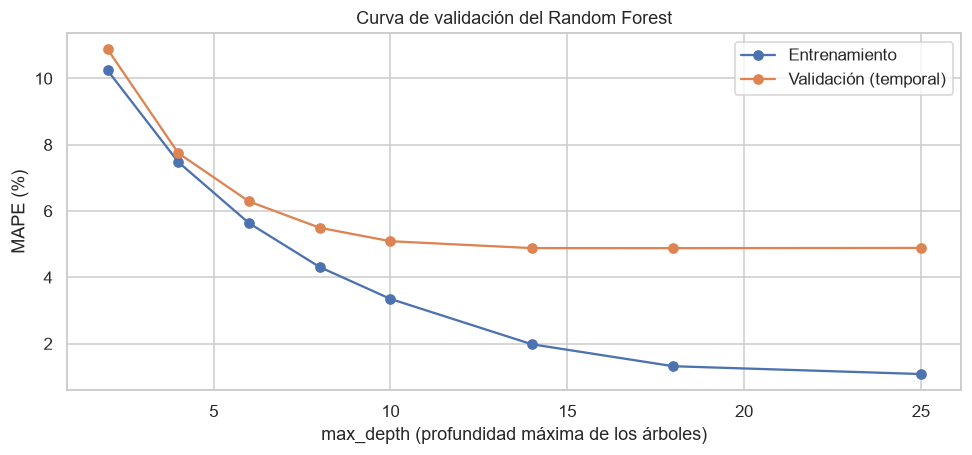

,max_depth,MAPE_train_%,MAPE_validacion_%
0,2,10.24,10.88
1,4,7.48,7.75
2,6,5.63,6.29
3,8,4.31,5.49
4,10,3.35,5.09
5,14,1.98,4.88
6,18,1.32,4.88
7,25,1.08,4.89


In [13]:
profundidades = [2, 4, 6, 8, 10, 14, 18, 25]
mape_train, mape_val = validation_curve(
    RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=SEMILLA),
    X_train, y_train,
    param_name="max_depth", param_range=profundidades,
    cv=cv_temporal, scoring="neg_mean_absolute_percentage_error", n_jobs=1,
)
curva = pd.DataFrame({
    "max_depth": profundidades,
    "MAPE_train_%": -mape_train.mean(axis=1) * 100,
    "MAPE_validacion_%": -mape_val.mean(axis=1) * 100,
})

fig, ax = plt.subplots(figsize=(9, 4.3))
ax.plot(curva.max_depth, curva["MAPE_train_%"], marker="o", label="Entrenamiento")
ax.plot(curva.max_depth, curva["MAPE_validacion_%"], marker="o", label="Validación (temporal)")
ax.set(title="Curva de validación del Random Forest", xlabel="max_depth (profundidad máxima de los árboles)", ylabel="MAPE (%)")
ax.legend()
guardar("curva_validacion_rf")
curva.round(2)

Lectura de la curva:

- Con árboles muy poco profundos (2–4) el modelo es demasiado simple y se equivoca tanto en train como en validación: **underfitting**.
- Al aumentar la profundidad, el error de entrenamiento sigue bajando, pero el de validación deja de mejorar. La distancia creciente entre las dos curvas es el **overfitting**: el modelo aprende detalles del entrenamiento que no se repiten en el futuro.

La profundidad conveniente es la que minimiza el error de **validación**, no el de entrenamiento.

### 8.2 Optimización de hiperparámetros

Se buscan varios hiperparámetros a la vez con `RandomizedSearchCV`: prueba combinaciones al azar dentro de un rango y se queda con la de menor error en la validación cruzada temporal. Es más eficiente que probar todas las combinaciones (`GridSearchCV`).

- `max_depth`: profundidad máxima de cada árbol.
- `min_samples_leaf`: mínimo de horas en cada hoja. Valores más altos obligan al árbol a generalizar.
- `max_features`: cuántas variables considera cada corte. Usar menos variables hace que los árboles sean más distintos entre sí y el promedio, más robusto.

In [14]:
busqueda_rf = RandomizedSearchCV(
    RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=SEMILLA),
    param_distributions={
        "max_depth": [8, 10, 12, 14, 16, 20, None],
        "min_samples_leaf": [1, 3, 5, 10, 20, 40],
        "max_features": [0.5, 0.7, 1.0],
    },
    n_iter=20, cv=cv_temporal, scoring="neg_mean_absolute_percentage_error",
    random_state=SEMILLA, n_jobs=1,
)
busqueda_rf.fit(X_train, y_train)

print("Mejores hiperparámetros:", busqueda_rf.best_params_)
print(f"MAPE validación cruzada: {-busqueda_rf.best_score_ * 100:.2f} %")

Mejores hiperparámetros: {'min_samples_leaf': 5, 'max_features': 0.7, 'max_depth': None}
MAPE validación cruzada: 4.80 %


## 9. Comparación: Gradient Boosting

Como comparación se entrena un **Gradient Boosting** (`HistGradientBoostingRegressor`). A diferencia del Random Forest, que promedia árboles independientes, el boosting construye los árboles **en secuencia**: cada uno corrige los errores de los anteriores. Suele ser más preciso, pero tiene más hiperparámetros sensibles al overfitting, como la tasa de aprendizaje y la cantidad de iteraciones.

Un detalle importante: con más de 10.000 filas, `HistGradientBoostingRegressor` activa por defecto el *early stopping*, que separa **al azar** una parte de los datos de entrenamiento para decidir cuándo dejar de agregar árboles. Eso rompería la regla de respetar el orden del tiempo. Se desactiva con `early_stopping=False`: la cantidad de árboles (`max_iter`) se elige como cualquier otro hiperparámetro, con la validación cruzada temporal.

In [15]:
busqueda_gb = RandomizedSearchCV(
    # early_stopping=False: sin validación interna al azar; max_iter se elige con la validación temporal
    HistGradientBoostingRegressor(early_stopping=False, random_state=SEMILLA),
    param_distributions={
        "learning_rate": [0.02, 0.05, 0.1],
        "max_iter": [200, 400, 800],
        "max_depth": [None, 6, 10],
        "min_samples_leaf": [20, 50, 100],
        "l2_regularization": [0.0, 0.1, 1.0],
    },
    n_iter=20, cv=cv_temporal, scoring="neg_mean_absolute_percentage_error",
    random_state=SEMILLA, n_jobs=1,
)
busqueda_gb.fit(X_train, y_train)

print("Mejores hiperparámetros:", busqueda_gb.best_params_)
print(f"MAPE validación cruzada: {-busqueda_gb.best_score_ * 100:.2f} %")

Mejores hiperparámetros: {'min_samples_leaf': 100, 'max_iter': 200, 'max_depth': 10, 'learning_rate': 0.05, 'l2_regularization': 1.0}
MAPE validación cruzada: 4.52 %


## 10. Selección del modelo

El modelo se elige con el error de **validación cruzada**, no con el de test. Si se eligiera mirando el test, el test dejaría de ser una medición imparcial del desempeño futuro.

In [16]:
seleccion = pd.DataFrame({
    "modelo": ["Regresión lineal", "Random Forest", "Gradient Boosting"],
    "MAPE_validacion_%": [cv_lineal.mean() * 100, -busqueda_rf.best_score_ * 100, -busqueda_gb.best_score_ * 100],
}).round(2).sort_values("MAPE_validacion_%")
seleccion

,modelo,MAPE_validacion_%
2,Gradient Boosting,4.52
1,Random Forest,4.80
0,Regresión lineal,6.33


## 11. Evaluación final en test (2025 → jul-2026)

Ahora sí se miden todos los modelos en el período de test, que ninguno vio durante el entrenamiento ni la selección.

La tabla principal usa la **temperatura pronosticada**, que es el escenario real de operación. Después se compara con la temperatura observada para ver cuánto empeora el modelo por el error del pronóstico del tiempo.

In [17]:
modelo_rf = busqueda_rf.best_estimator_
modelo_gb = busqueda_gb.best_estimator_
modelos = {"Regresión lineal": modelo_lineal, "Random Forest": modelo_rf, "Gradient Boosting": modelo_gb}

# escenario real: temperatura pronosticada 24 h antes (tabla principal)
predicciones = {nombre: m.predict(X_test_pron) for nombre, m in modelos.items()}
# escenario ideal: temperatura observada, como si el pronóstico del tiempo fuera perfecto
predicciones_obs = {nombre: m.predict(X_test) for nombre, m in modelos.items()}

for nombre, pred in predicciones.items():
    resultados.append(evaluar(nombre, y_test, pred))

tabla_test = pd.DataFrame(resultados).set_index("modelo")
tabla_test

,MAPE_%,WAPE_%,RMSE_MWh,MAE_MWh,sesgo_MWh
modelo,,,,,
Referencia: perfil promedio,7.57,7.85,1724,1284,423
Referencia: misma hora semana anterior,9.12,9.22,2097,1509,9
Regresión lineal,6.07,6.16,1321,1007,275
Random Forest,4.27,4.41,995,721,238
Gradient Boosting,4.07,4.21,961,688,234


In [18]:
# cuánto empeora cada modelo por usar el pronóstico del tiempo en lugar de la temperatura real
costo_pronostico = pd.DataFrame({
    "MAPE_temp_observada_%": {n: mean_absolute_percentage_error(y_test, p) * 100 for n, p in predicciones_obs.items()},
    "MAPE_temp_pronosticada_%": {n: mean_absolute_percentage_error(y_test, p) * 100 for n, p in predicciones.items()},
})
costo_pronostico["diferencia_pp"] = costo_pronostico["MAPE_temp_pronosticada_%"] - costo_pronostico["MAPE_temp_observada_%"]
costo_pronostico.round(2)

,MAPE_temp_observada_%,MAPE_temp_pronosticada_%,diferencia_pp
Regresión lineal,6.02,6.07,0.05
Random Forest,4.17,4.27,0.10
Gradient Boosting,3.98,4.07,0.09


**El error del pronóstico del tiempo casi no mueve el resultado:** el Gradient Boosting pasa de 3,98 % con la temperatura observada a 4,07 % con la que se conocía al emitir (+0,09 puntos). Hay tres razones:

- El pronóstico de ECMWF para Buenos Aires, con 12 a 35 horas de anticipación, es bueno: se equivoca 0,7 °C en promedio y sin sesgo.
- Las variables más usadas (`temp_24h`, `hdd`, `cdd`) son promedios de 24 horas: al promediar, los errores de distintas horas se compensan en parte.
- El error del modelo (~4 %) viene sobre todo de otras fuentes: el cambio de nivel de la demanda que no conoce y las olas de calor nacionales.

**Cómo cambió con la corrección del momento de emisión.** La versión anterior usaba el pronóstico hecho 24 h antes de *cada* hora y daba 4,06 %. El resultado casi no cambia, así que la conclusión se mantiene. Lo que cambia es que ahora el experimento coincide con lo que se haría en la operación, bajo el supuesto de emitir a las 12:00 del día anterior.

In [19]:
# error de entrenamiento vs test de cada modelo: una diferencia grande indicaría overfitting.
# Para medir overfitting se compara con el test con temperatura observada: mismo tipo de dato que en train.
pd.DataFrame({
    "MAPE_train_%": {n: mean_absolute_percentage_error(y_train, m.predict(X_train)) * 100 for n, m in modelos.items()},
    "MAPE_test_obs_%": {n: mean_absolute_percentage_error(y_test, p) * 100 for n, p in predicciones_obs.items()},
}).round(2)

,MAPE_train_%,MAPE_test_obs_%
Regresión lineal,6.12,6.02
Random Forest,2.56,4.17
Gradient Boosting,3.43,3.98


### 11.1 Predicción vs. realidad

Dos semanas del test, una de verano y una de invierno, con el mejor modelo de validación y la temperatura pronosticada.

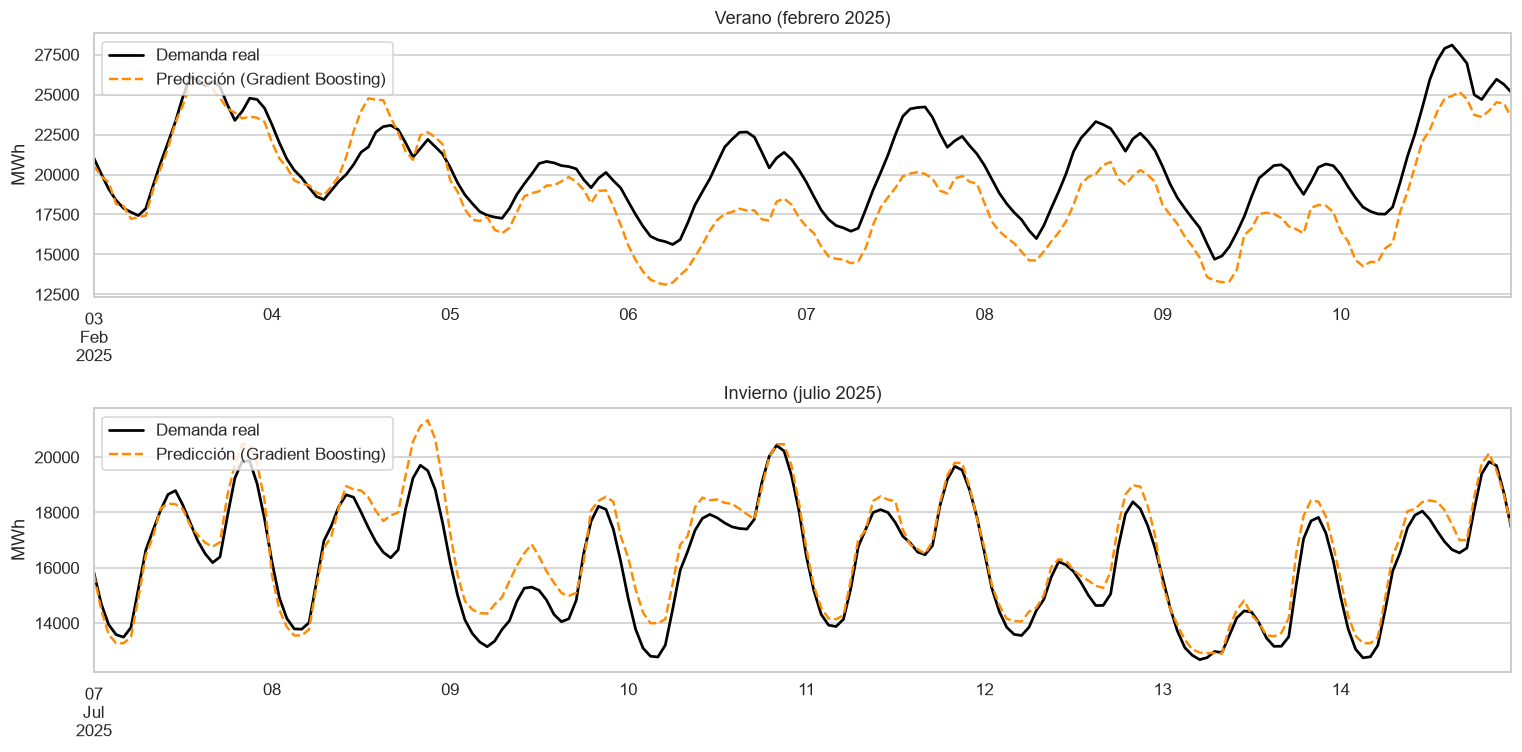

In [20]:
MEJOR = seleccion.iloc[0]["modelo"]
pred_mejor = pd.Series(predicciones[MEJOR], index=t_test.values)
real = pd.Series(y_test.values, index=t_test.values)

semanas = {"Verano (febrero 2025)": ("2025-02-03", "2025-02-10"), "Invierno (julio 2025)": ("2025-07-07", "2025-07-14")}
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
for ax, (titulo, (desde, hasta)) in zip(axes, semanas.items()):
    real[desde:hasta].plot(ax=ax, lw=1.8, color="black", label="Demanda real")
    pred_mejor[desde:hasta].plot(ax=ax, lw=1.6, color="darkorange", ls="--", label=f"Predicción ({MEJOR})")
    ax.set(title=titulo, ylabel="MWh", xlabel="")
    ax.legend(loc="upper left")
guardar("prediccion_vs_real")

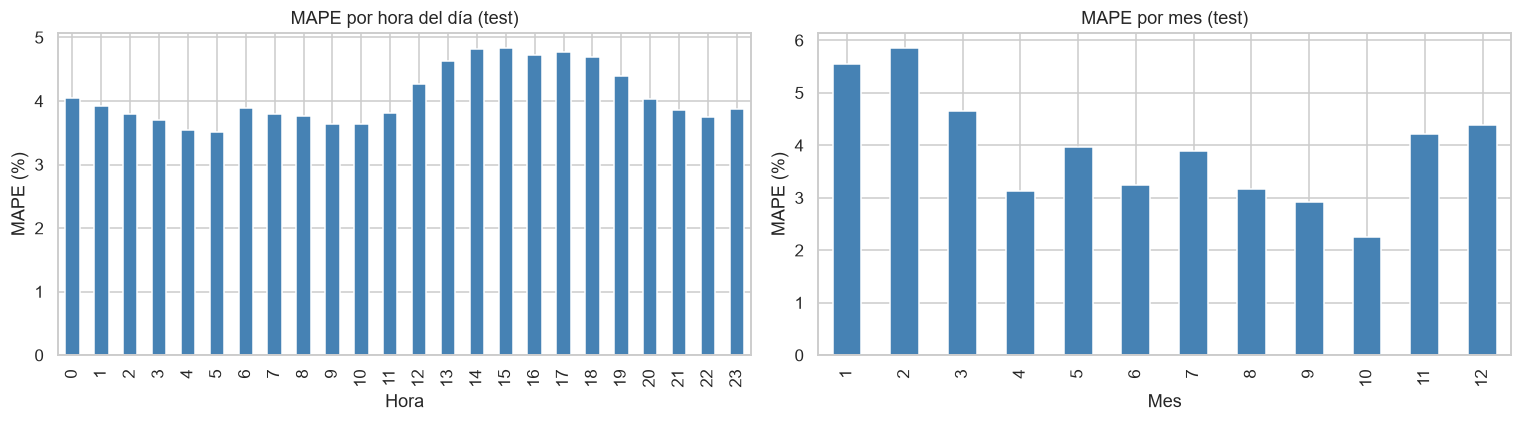

In [21]:
# MAPE del mejor modelo según la hora del día y el mes
error_pct = (real - pred_mejor).abs() / real * 100
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
error_pct.groupby(error_pct.index.hour).mean().plot.bar(ax=axes[0], color="steelblue")
axes[0].set(title="MAPE por hora del día (test)", xlabel="Hora", ylabel="MAPE (%)")
error_pct.groupby(error_pct.index.month).mean().plot.bar(ax=axes[1], color="steelblue")
axes[1].set(title="MAPE por mes (test)", xlabel="Mes", ylabel="MAPE (%)")
guardar("error_por_hora_y_mes")

In [22]:
# error medio (real - predicción) por año: si es siempre positivo, el modelo subestima
sesgo = (real - pred_mejor)
# ¿cuánto creció la demanda? 2026 solo tiene enero a julio: hay que comparar períodos equivalentes
serie_demanda = df.set_index("timestamp")["demanda_mwh"]
ene_jul = {anio: serie_demanda[f"{anio}-01":f"{anio}-07"].mean() for anio in (2025, 2026)}
print(f"Ene–jul 2026 vs. todo 2025 (mezcla estaciones distintas): {serie_demanda['2026'].mean() / serie_demanda['2025'].mean() - 1:+.1%}")
print(f"Ene–jul 2026 vs. ene–jul 2025 (comparable):               {ene_jul[2026] / ene_jul[2025] - 1:+.1%}")

pd.DataFrame({
    "sesgo_MWh": sesgo.groupby(sesgo.index.year).mean().round(0),
    "sesgo_%": (sesgo / real * 100).groupby(sesgo.index.year).mean().round(2),
})

Ene–jul 2026 vs. todo 2025 (mezcla estaciones distintas): +4.0%
Ene–jul 2026 vs. ene–jul 2025 (comparable):               +0.9%


,sesgo_MWh,sesgo_%
2025,129.0,0.53
2026,414.0,2.37


**El modelo subestima, sobre todo en 2026:** 0,5 % en 2025 y 2,4 % en 2026.

Es tentador atribuirlo al crecimiento de la demanda, pero hay que comparar bien. La demanda media de enero–julio de 2026 es un 4,0 % mayor que la de **todo** 2025, pero esa comparación mezcla estaciones distintas: enero–julio incluye el verano y el invierno, los meses de mayor demanda, y no la primavera. Comparando períodos equivalentes (enero–julio de cada año), el crecimiento es de solo **0,9 %**.

O sea, el aumento de la demanda media explica solo una parte de la subestimación. El resto puede venir del clima, del calendario o de cambios en cómo responde la demanda a la temperatura, y separar esos efectos requeriría un análisis de los residuos ajustado por clima, que queda fuera de este trabajo. Lo que sí es seguro es que el modelo aprende el nivel de 2021–2024 y que los árboles no extrapolan: nunca predicen valores más altos que los que vieron en entrenamiento.

En la semana de verano, el 10 de febrero de 2025 (récord histórico de la serie, 28.094 MW) el modelo se queda unos 3.000 MW corto. Fue una ola de calor nacional, y una sola temperatura de Buenos Aires no la refleja completa. El error es mayor en **enero–febrero** y en las **horas de la tarde (13–18 h)**: son las horas de pico de verano, las más difíciles y las más importantes para el operador.

### 11.2 ¿Qué variables usa el modelo?

La **importancia por permutación** mide cuánto empeora el error cuando se "desordenan" al azar los valores de una variable en el test. Si el error sube mucho, el modelo depende de esa variable. Tiene una ventaja sobre la importancia interna de los árboles: se mide sobre datos que el modelo no vio.

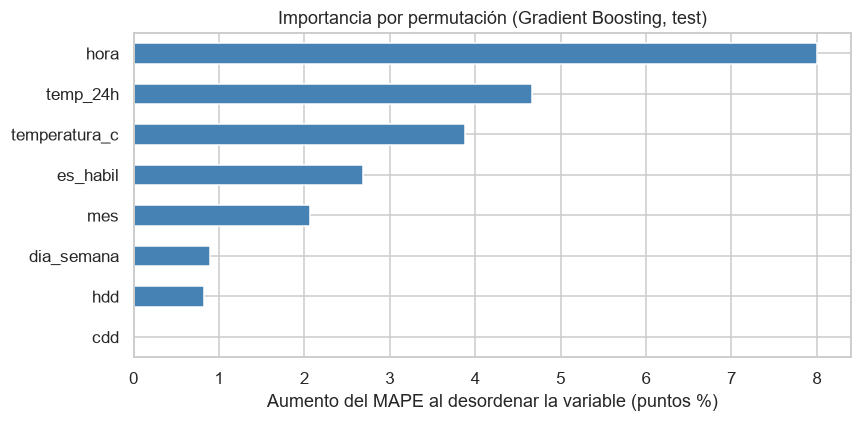

hora             8.00
temp_24h         4.67
temperatura_c    3.88
es_habil         2.69
mes              2.07
dia_semana       0.89
hdd              0.83
cdd              0.00
dtype: float64

In [23]:
importancia = permutation_importance(
    modelos[MEJOR], X_test_pron, y_test, n_repeats=5, random_state=SEMILLA,
    scoring="neg_mean_absolute_percentage_error",
)
# aumento del MAPE (en puntos porcentuales) al desordenar cada variable
imp = pd.Series(importancia.importances_mean * 100, index=VARIABLES).sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
imp.plot.barh(ax=ax, color="steelblue")
ax.set(title=f"Importancia por permutación ({MEJOR}, test)", xlabel="Aumento del MAPE al desordenar la variable (puntos %)")
guardar("importancia_variables")
imp.sort_values(ascending=False).round(2)

- **`hora` es la variable más importante:** la curva diaria explica la mayor parte de la variación de la demanda.
- Le siguen las de **temperatura** (`temp_24h` y `temperatura_c`) y el **calendario** (`es_habil`, `mes`).
- `cdd` aparece con importancia ~0 y `hdd` baja. No significa que el calor no importe: llevan la misma información que `temp_24h`, de la que se calculan. Cuando se desordena `cdd`, el modelo sigue teniendo la temperatura en `temp_24h`. Es una limitación conocida de la importancia por permutación con variables correlacionadas: reparte (o esconde) la importancia entre ellas.

### 11.3 Días de calor extremo

Las olas de calor son los momentos de mayor riesgo para el sistema: la demanda bate récords y cualquier error de pronóstico se paga caro. Para medir cómo le va al modelo en esos días se definen los **días de calor extremo** como los que tuvieron una temperatura máxima por encima del **percentil 95 de las máximas diarias del período de entrenamiento**. Es el mismo criterio de percentiles que usa el SMN para definir olas de calor, y el umbral se calcula solo con train.

Se usa la temperatura **observada** para clasificar los días, porque la pregunta es qué pasó en los días que efectivamente fueron muy calurosos.

In [24]:
# temperatura máxima observada de cada día y umbral de calor extremo (percentil 95 de las máximas de train)
tmax_dia = df.groupby(df.timestamp.dt.normalize())["temperatura_c"].max()
UMBRAL_CALOR = tmax_dia[tmax_dia.index < FIN_TRAIN].quantile(0.95)
dias_calor = tmax_dia[(tmax_dia.index >= FIN_TRAIN) & (tmax_dia > UMBRAL_CALOR)].index

es_calor = t_test.dt.normalize().isin(dias_calor).values
print(f"Umbral de calor extremo: máxima diaria > {UMBRAL_CALOR:.1f} °C")
print(f"Días de calor extremo en el test: {len(dias_calor)} de {t_test.dt.normalize().nunique()}")

pd.DataFrame([
    evaluar("Días de calor extremo", real[es_calor], pred_mejor[es_calor]),
    evaluar("Resto de los días", real[~es_calor], pred_mejor[~es_calor]),
]).set_index("modelo")

Umbral de calor extremo: máxima diaria > 30.9 °C
Días de calor extremo en el test: 53 de 577


,MAPE_%,WAPE_%,RMSE_MWh,MAE_MWh,sesgo_MWh
modelo,,,,,
Días de calor extremo,4.96,4.96,1282,965,43
Resto de los días,3.98,4.11,923,660,253


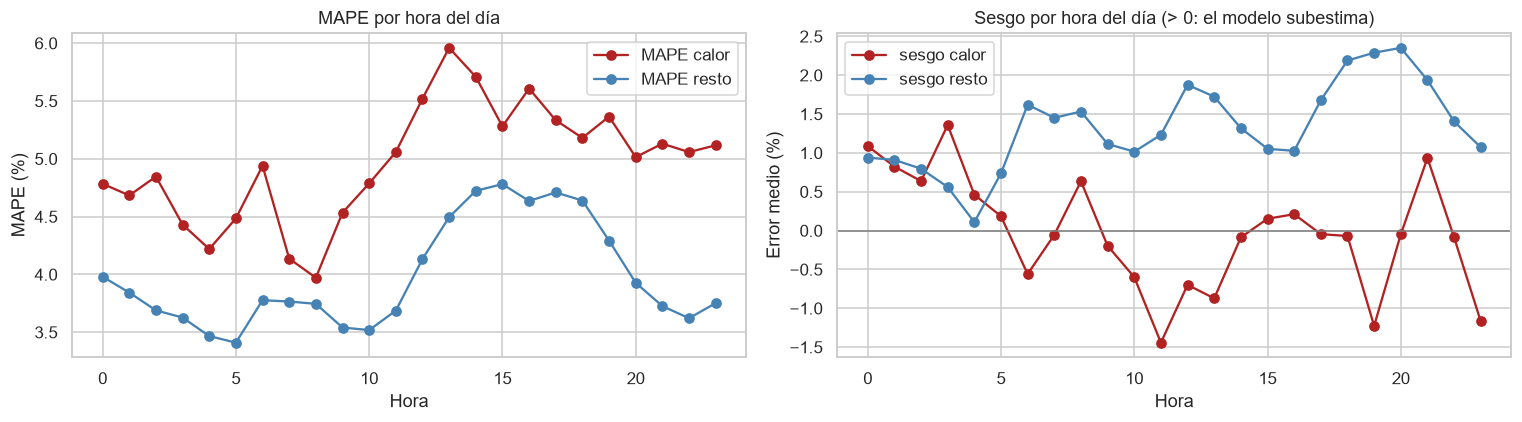

In [25]:
# error por hora del día: días de calor extremo vs. resto
error_rel = (real - pred_mejor) / real * 100   # con signo: > 0 el modelo subestima
por_hora = pd.DataFrame({
    "MAPE calor": error_rel[es_calor].abs().groupby(error_rel.index[es_calor].hour).mean(),
    "MAPE resto": error_rel[~es_calor].abs().groupby(error_rel.index[~es_calor].hour).mean(),
    "sesgo calor": error_rel[es_calor].groupby(error_rel.index[es_calor].hour).mean(),
    "sesgo resto": error_rel[~es_calor].groupby(error_rel.index[~es_calor].hour).mean(),
})

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
por_hora[["MAPE calor", "MAPE resto"]].plot(ax=axes[0], marker="o", color=["firebrick", "steelblue"])
axes[0].set(title="MAPE por hora del día", xlabel="Hora", ylabel="MAPE (%)")
por_hora[["sesgo calor", "sesgo resto"]].plot(ax=axes[1], marker="o", color=["firebrick", "steelblue"])
axes[1].axhline(0, color="gray", lw=1)
axes[1].set(title="Sesgo por hora del día (> 0: el modelo subestima)", xlabel="Hora", ylabel="Error medio (%)")
guardar("error_dias_calor")

**El modelo se equivoca un 25 % más en los días de calor extremo** (MAPE 5,0 % contra 4,0 %; RMSE 1.282 contra 923 MWh). El error es mayor a **todas las horas** del día, no solo a la tarde. El máximo está a las **13–14 h** (~6 %), cuando el aire acondicionado mueve la demanda.

Lo que **no** aparece es que en esos días el modelo siempre se quede corto: su sesgo en los días de calor es casi nulo (43 MWh). Falla **para los dos lados**: algunos días de calor sobrestima y otros, como el récord del 10/02/2025, subestima por mucho.

Que en el resto de los días el sesgo sea positivo (subestima) no es por el clima: es el cambio de nivel de la demanda visto en 11.1, que se ataca en 11.4.

Conclusión práctica: en los días de calor extremo el pronóstico es **más incierto**, no sistemáticamente bajo. Eso es lo que se cuantifica con los intervalos de predicción de 11.5.

### 11.4 Tendencia: reentrenamiento mensual

En 11.1 se vio que el modelo subestima, sobre todo en 2026: aprende el nivel de demanda de 2021–2024 y no sabe que ese nivel cambió. En la operación real un modelo no queda congelado: se **reentrena periódicamente** con los datos nuevos.

Se simula exactamente eso: el día 1 de cada mes del test se reentrena el Gradient Boosting (mismos hiperparámetros) con toda la demanda conocida hasta ese día, y se predice ese mes. Así nunca se usa información del futuro. Se supone que el día 1 ya se conoce la demanda de todo el mes anterior: es así con la medición en tiempo real, aunque la planilla mensual definitiva de CAMMESA se publica después.

Hay una decisión más: **con cuánta historia reentrenar**.

- **Ventana expansiva:** todo el historial desde 2021. Tiene más datos, pero los meses nuevos pesan poco frente a años de historia.
- **Ventana móvil:** solo los últimos N meses. Se adapta más rápido al nivel reciente, pero aprende con menos ejemplos.

El tamaño de la ventana es un hiperparámetro y, como siempre, **se elige sin mirar el test**: se simula el reentrenamiento mensual durante 2024, que está dentro del período de entrenamiento. Como criterio se usa el **WAPE**, que pondera más las horas de mayor demanda, las que importan para el despacho. En 2024 no hay pronósticos del tiempo completos, así que esta validación usa temperatura observada.

In [26]:
PARAMS_GB = {**busqueda_gb.best_params_, "early_stopping": False, "random_state": SEMILLA}


def reentrenar_mensual(X_pred, t_pred, ventana_meses=None, cuantiles=()):
    """Simula que el Gradient Boosting se reentrena el día 1 de cada mes con la demanda conocida hasta ese día
    y predice ese mes.

    ventana_meses: None = todo el historial; N = solo los últimos N meses.
    cuantiles: además de la predicción central, entrena modelos de regresión cuantil (sección 11.5).
    Devuelve un DataFrame con una columna "pred" y una por cada cuantil pedido.
    """
    salida = pd.DataFrame(index=X_pred.index, dtype=float)
    for inicio in pd.date_range(t_pred.min(), t_pred.max(), freq="MS"):
        fin = inicio + pd.offsets.MonthBegin(1)
        disponible = df["timestamp"] < inicio   # solo lo que se conoce el día del reentrenamiento
        if ventana_meses is not None:
            disponible &= df["timestamp"] >= inicio - pd.DateOffset(months=ventana_meses)
        X_ent, y_ent = df.loc[disponible, VARIABLES], df.loc[disponible, "demanda_mwh"]
        en_mes = ((t_pred >= inicio) & (t_pred < fin)).values

        salida.loc[en_mes, "pred"] = HistGradientBoostingRegressor(**PARAMS_GB).fit(X_ent, y_ent).predict(X_pred[en_mes])
        for q in cuantiles:
            modelo_q = HistGradientBoostingRegressor(loss="quantile", quantile=q, **PARAMS_GB).fit(X_ent, y_ent)
            salida.loc[en_mes, f"q{round(q * 100)}"] = modelo_q.predict(X_pred[en_mes])
    return salida


# validación: reentrenamiento mensual durante 2024 (dentro de train), con distintas ventanas
en_val = (df["timestamp"] >= "2024-01-01") & en_train
X_val, y_val, t_val = df.loc[en_val, VARIABLES], df.loc[en_val, "demanda_mwh"], df.loc[en_val, "timestamp"]

ventanas = {"Expansiva (todo el historial)": None, "Últimos 36 meses": 36, "Últimos 24 meses": 24, "Últimos 12 meses": 12}
validacion_ventanas = pd.DataFrame([
    evaluar(nombre, y_val, reentrenar_mensual(X_val, t_val, v)["pred"]) for nombre, v in ventanas.items()
]).set_index("modelo")
validacion_ventanas

,MAPE_%,WAPE_%,RMSE_MWh,MAE_MWh,sesgo_MWh
modelo,,,,,
Expansiva (todo el historial),3.98,4.06,873,648,90
Últimos 36 meses,3.97,4.05,874,647,96
Últimos 24 meses,3.97,3.99,861,637,-89
Últimos 12 meses,4.31,4.31,909,688,-115


In [27]:
# ventana elegida: la de menor WAPE en la validación de 2024
NOMBRE_VENTANA = validacion_ventanas["WAPE_%"].idxmin()
VENTANA = ventanas[NOMBRE_VENTANA]
print(f"Ventana elegida: {NOMBRE_VENTANA}")

Ventana elegida: Últimos 24 meses


En 2024 las ventanas expansiva, de 36 y de 24 meses quedan prácticamente empatadas en MAPE (3,97–3,98 %). Por WAPE gana la de **24 meses** (3,99 %), y es la que se usa. Tiene además una lógica física: ve **dos veranos y dos inviernos** completos y le da más peso al nivel reciente de la demanda.

La validación casi no distingue entre ventanas porque en 2024 la demanda **cayó** respecto de 2023 (recesión): no había un cambio de nivel que corregir. La de 12 meses es peor porque, con un solo año, cada estación tiene muy pocos ejemplos para aprender.

In [28]:
# test: modelo fijo (entrenado una vez con 2021–2024) vs. reentrenamiento mensual, con temperatura pronosticada.
# El reentrenamiento con la ventana elegida también entrena los cuantiles 10 y 90 que se usan en 11.5.
reent_expansiva = reentrenar_mensual(X_test_pron, t_test, None)
reent_elegida = reentrenar_mensual(X_test_pron, t_test, VENTANA, cuantiles=(0.1, 0.9))

pred_reent = pd.Series(reent_elegida["pred"].values, index=t_test.values)
tabla_reent = pd.DataFrame([
    evaluar("Gradient Boosting fijo", y_test, predicciones["Gradient Boosting"]),
    evaluar("Reentrenamiento mensual, ventana expansiva", y_test, reent_expansiva["pred"]),
    evaluar(f"Reentrenamiento mensual, {NOMBRE_VENTANA.lower()}", y_test, pred_reent),
]).set_index("modelo")
tabla_reent

,MAPE_%,WAPE_%,RMSE_MWh,MAE_MWh,sesgo_MWh
modelo,,,,,
Gradient Boosting fijo,4.07,4.21,961,688,234
"Reentrenamiento mensual, ventana expansiva",4.02,4.15,949,679,216
"Reentrenamiento mensual, últimos 24 meses",4.07,4.17,930,682,67


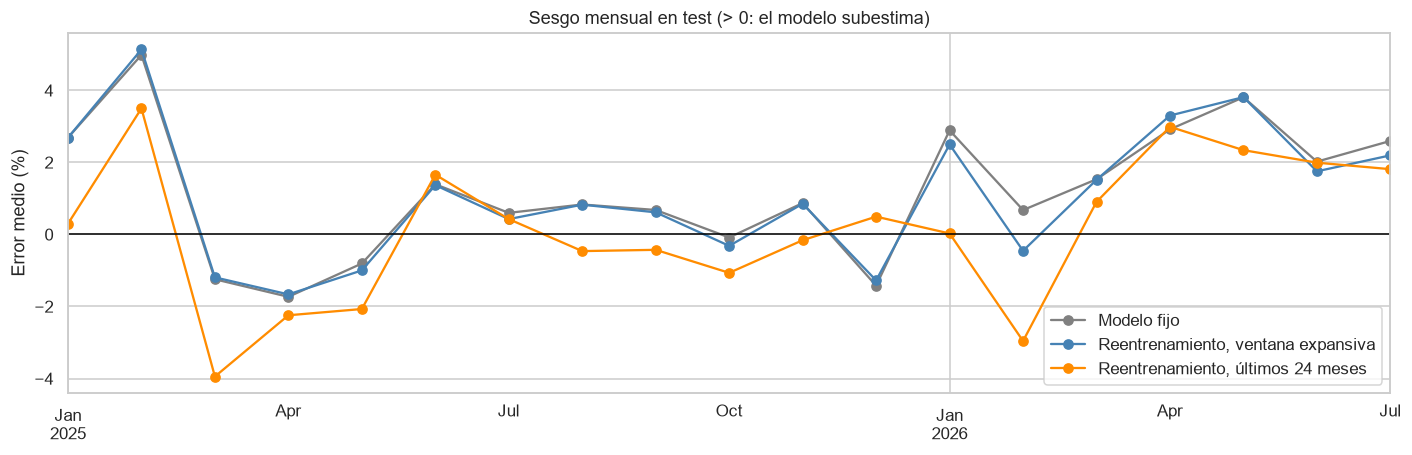

,Modelo fijo,"Reentrenamiento, ventana expansiva","Reentrenamiento, últimos 24 meses"
2025,0.56,0.54,-0.33
2026,2.35,2.09,1.01


In [29]:
# sesgo mensual (%): ¿el reentrenamiento corrige la subestimación creciente?
def sesgo_mensual(pred):
    error = (real - np.asarray(pred)) / real * 100
    return error.groupby(error.index.to_period("M")).mean()


sesgos = pd.DataFrame({
    "Modelo fijo": sesgo_mensual(predicciones["Gradient Boosting"]),
    "Reentrenamiento, ventana expansiva": sesgo_mensual(reent_expansiva["pred"]),
    f"Reentrenamiento, {NOMBRE_VENTANA.lower()}": sesgo_mensual(pred_reent),
})

fig, ax = plt.subplots(figsize=(13, 4.3))
sesgos.index = sesgos.index.to_timestamp()
sesgos.plot(ax=ax, marker="o", color=["gray", "steelblue", "darkorange"])
ax.axhline(0, color="black", lw=1)
ax.set(title="Sesgo mensual en test (> 0: el modelo subestima)", ylabel="Error medio (%)", xlabel="")
guardar("sesgo_mensual_reentrenamiento")

# sesgo por año
sesgos.groupby(sesgos.index.year).mean().round(2)

**El reentrenamiento con ventana de 24 meses reduce el sesgo, no el error total:**

- El **sesgo** total baja de 234 a 67 MWh, y en 2026, de 2,4 % a 1,0 %. Es su aporte principal.
- El **MAPE** no mejora (4,07 % en los dos casos). Baja un poco el **RMSE** (961 → 930 MWh), así que se reducen algo los errores grandes.
- La **ventana expansiva** casi no corrige el sesgo (2026: de 2,4 % a 2,1 %), pero en el test tiene un MAPE apenas menor (4,02 %). La elección depende del objetivo: si importa no quedarse sistemáticamente corto, conviene la de 24 meses; si importa solo el error promedio, las dos son equivalentes.
- En 2025 el modelo de 24 meses pasa a sobrestimar un poco (−0,3 %), porque aprende de 2023–2024, años de demanda estancada.

Es una alternativa que **reduce el sesgo** en el período estudiado, no una mejora general del modelo. Las secciones siguientes usan esta versión, porque es la que se usaría para no quedarse corto.

### 11.5 Intervalos de predicción

Un pronóstico puntual ("mañana a las 15 h habrá 24.000 MW") no dice nada sobre la **incertidumbre**. Una banda ("con 80 % de probabilidad, entre 22.800 y 25.100 MW") cuantifica la **incertidumbre** del pronóstico de demanda. Es un insumo para estudiar la flexibilidad que necesita el sistema, pero **no es la reserva**: la reserva de CAMMESA tiene varios componentes, con distintos tiempos de respuesta, y también cubre fallas de generación y otros riesgos que no son errores de demanda.

Se construye con **regresión cuantil**: el mismo Gradient Boosting, pero entrenado con otra función de pérdida (`loss="quantile"`). En vez de apuntar al valor medio, cada modelo apunta a un percentil:

- El modelo del **cuantil 10** busca un valor que la demanda real supere el 90 % de las veces (borde inferior).
- El modelo del **cuantil 90** busca un valor que la demanda real supere solo el 10 % de las veces (borde superior).

Entre los dos queda una banda del 80 %. Los modelos se reentrenan cada mes igual que la predicción central (se entrenaron en la celda de 11.4).

Se evalúa con dos números:

- **Cobertura:** en qué porcentaje de las horas la demanda real cayó dentro de la banda. Si el intervalo está bien calibrado, debería rondar el 80 %.
- **Ancho medio** en MW: una banda angosta es más útil, siempre que la cobertura se mantenga.

Las dos cosas se miden también por separado: cuántas horas quedan **por encima** de la banda (lo esperable es 10 %) y cuántas **por debajo** (otro 10 %).

Además:

- **Interval score:** resume ancho y cobertura en un solo número (más bajo es mejor). Suma el ancho de la banda y una penalización por cada hora que la demanda queda afuera, proporcional a cuánto se escapó.
- **Días completos cubiertos:** en qué porcentaje de los días las 24 horas quedan dentro. Una banda del 80 % por hora **no** promete cubrir el día entero; este número muestra la diferencia entre los dos objetivos.

In [30]:
q10 = pd.Series(reent_elegida["q10"].values, index=t_test.values)
q90 = pd.Series(reent_elegida["q90"].values, index=t_test.values)


def evaluar_intervalo(nombre, inferior, superior):
    """Cobertura y ancho de un intervalo de predicción en el test."""
    dentro = (real >= inferior) & (real <= superior)
    return {
        "intervalo": nombre,
        "cobertura_%": dentro.mean() * 100,
        "ancho_medio_MW": (superior - inferior).mean(),
        "real_arriba_%": (real > superior).mean() * 100,   # lo esperado: 10 %
        "real_abajo_%": (real < inferior).mean() * 100,    # lo esperado: 10 %
        "cobertura_dias_calor_%": dentro[es_calor].mean() * 100,
        # interval score para una banda del 80 % (alfa = 0,2): ancho + penalización por las horas fuera de la banda
        "interval_score_MW": ((superior - inferior)
                              + 2 / 0.2 * (inferior - real).clip(lower=0)
                              + 2 / 0.2 * (real - superior).clip(lower=0)).mean(),
        "dias_completos_cubiertos_%": dentro.groupby(dentro.index.normalize()).all().mean() * 100,
    }


pd.DataFrame([evaluar_intervalo("Cuantiles 10 y 90, sin calibrar", q10, q90)]).set_index("intervalo").round(1)

,cobertura_%,ancho_medio_MW,real_arriba_%,real_abajo_%,cobertura_dias_calor_%,interval_score_MW,dias_completos_cubiertos_%
intervalo,,,,,,,
"Cuantiles 10 y 90, sin calibrar",68.5,1786.4,17.5,13.9,69.3,3293.8,15.3


La banda queda **demasiado angosta**: cubre bastante menos que el 80 % prometido. Es un problema conocido de la regresión cuantil: los modelos aprenden la incertidumbre con los mismos datos con los que se entrenan, y ahí se equivocan menos que en datos nuevos. Además, en el test se suma el error del pronóstico del tiempo, que en entrenamiento no existe.

**Corrección: calibración conformal.** La idea es ajustar la banda según cuánto se equivocó el modelo **fuera de muestra** en el pasado reciente:

1. Para cada hora ya conocida se calcula un **puntaje**: cuánto quedó la demanda real afuera de la banda (si quedó adentro, el puntaje es negativo).
2. El día 1 de cada mes se toma el percentil 80 de los puntajes de los **12 meses anteriores** (un año, para que entren todas las estaciones).
3. Se ensancha la banda de ese mes en esa cantidad, para arriba y para abajo.

Si en el último año la banda cubrió menos de lo prometido, el ajuste la ensancha; si cubrió de más, la angosta (el puntaje puede ser negativo). Solo usa información del pasado, así que no hay fuga. Es una corrección **empírica**: como los errores de horas seguidas están correlacionados y los modelos cambian cada mes, no garantiza exactamente el 80 % en cada hora; hay que comprobarlo con los datos, como se hace abajo.

Para que el primer mes del test también tenga 12 meses de historia, se repite el reentrenamiento mensual durante 2024 (dentro de train) para obtener sus predicciones fuera de muestra. En 2024 esas predicciones usan temperatura observada, así que los primeros meses del test se calibran con errores algo más chicos que los que tendrán con el pronóstico del tiempo.

In [31]:
# predicciones cuantiles fuera de muestra de 2024, con el mismo esquema de reentrenamiento mensual
reent_val = reentrenar_mensual(X_val, t_val, VENTANA, cuantiles=(0.1, 0.9))

historia = pd.DataFrame({
    "timestamp": np.concatenate([t_val.values, t_test.values]),
    "real": np.concatenate([y_val.values, y_test.values]),
    "q10": np.concatenate([reent_val["q10"].values, reent_elegida["q10"].values]),
    "q90": np.concatenate([reent_val["q90"].values, reent_elegida["q90"].values]),
})
# puntaje de no conformidad: cuánto quedó la demanda afuera de la banda (negativo si quedó adentro)
historia["puntaje"] = np.maximum(historia["q10"] - historia["real"], historia["real"] - historia["q90"])

MESES_CALIBRACION = 12
ajuste = pd.Series(np.nan, index=t_test.values)
for inicio in pd.date_range(t_test.min(), t_test.max(), freq="MS"):
    previos = (historia["timestamp"] < inicio) & (historia["timestamp"] >= inicio - pd.DateOffset(months=MESES_CALIBRACION))
    en_mes = (ajuste.index >= inicio) & (ajuste.index < inicio + pd.offsets.MonthBegin(1))
    ajuste[en_mes] = np.quantile(historia.loc[previos, "puntaje"], 0.80)

q10_cal, q90_cal = q10 - ajuste, q90 + ajuste
pd.DataFrame([
    evaluar_intervalo("Cuantiles 10 y 90, sin calibrar", q10, q90),
    evaluar_intervalo("Calibrado (conformal, 12 meses)", q10_cal, q90_cal),
]).set_index("intervalo").round(1)

,cobertura_%,ancho_medio_MW,real_arriba_%,real_abajo_%,cobertura_dias_calor_%,interval_score_MW,dias_completos_cubiertos_%
intervalo,,,,,,,
"Cuantiles 10 y 90, sin calibrar",68.5,1786.4,17.5,13.9,69.3,3293.8,15.3
"Calibrado (conformal, 12 meses)",79.3,2186.5,12.4,8.2,76.6,3183.5,31.4


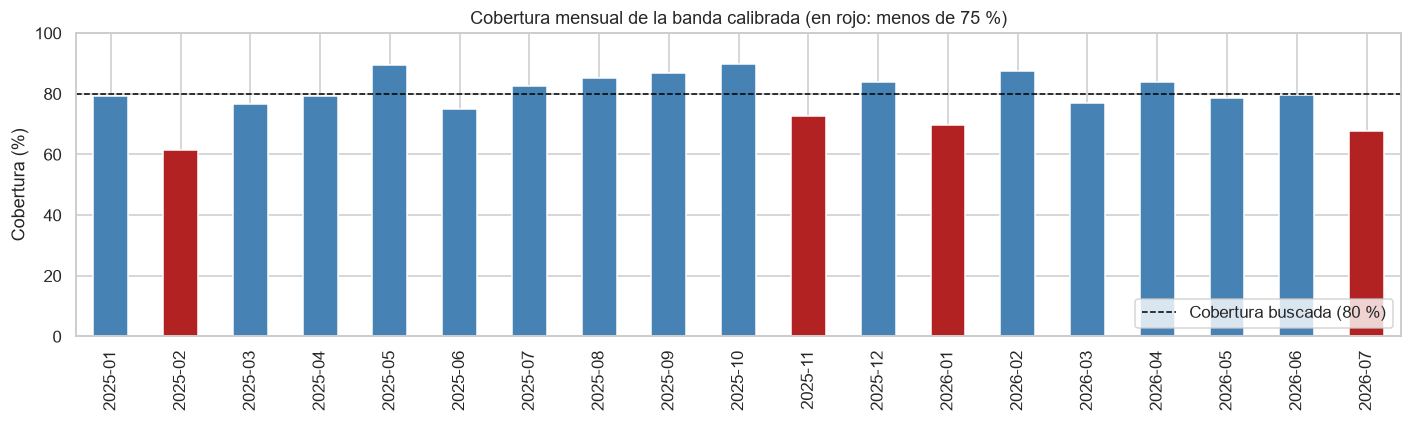

Meses con cobertura menor a 75 %: 4 de 19
Rango: 62 % (2025-02) a 90 % (2025-10)


In [32]:
# cobertura por mes: el promedio global puede esconder meses en que la banda falla
dentro_cal = (real >= q10_cal) & (real <= q90_cal)
cobertura_mensual = dentro_cal.groupby(dentro_cal.index.to_period("M")).mean() * 100

fig, ax = plt.subplots(figsize=(13, 4))
cobertura_mensual.plot.bar(ax=ax, color=np.where(cobertura_mensual < 75, "firebrick", "steelblue"))
ax.axhline(80, color="black", ls="--", lw=1, label="Cobertura buscada (80 %)")
ax.set(title="Cobertura mensual de la banda calibrada (en rojo: menos de 75 %)", ylabel="Cobertura (%)", xlabel="", ylim=(0, 100))
ax.legend(loc="lower right")
guardar("cobertura_mensual")
print(f"Meses con cobertura menor a 75 %: {(cobertura_mensual < 75).sum()} de {len(cobertura_mensual)}")
print(f"Rango: {cobertura_mensual.min():.0f} % ({cobertura_mensual.idxmin()}) a {cobertura_mensual.max():.0f} % ({cobertura_mensual.idxmax()})")

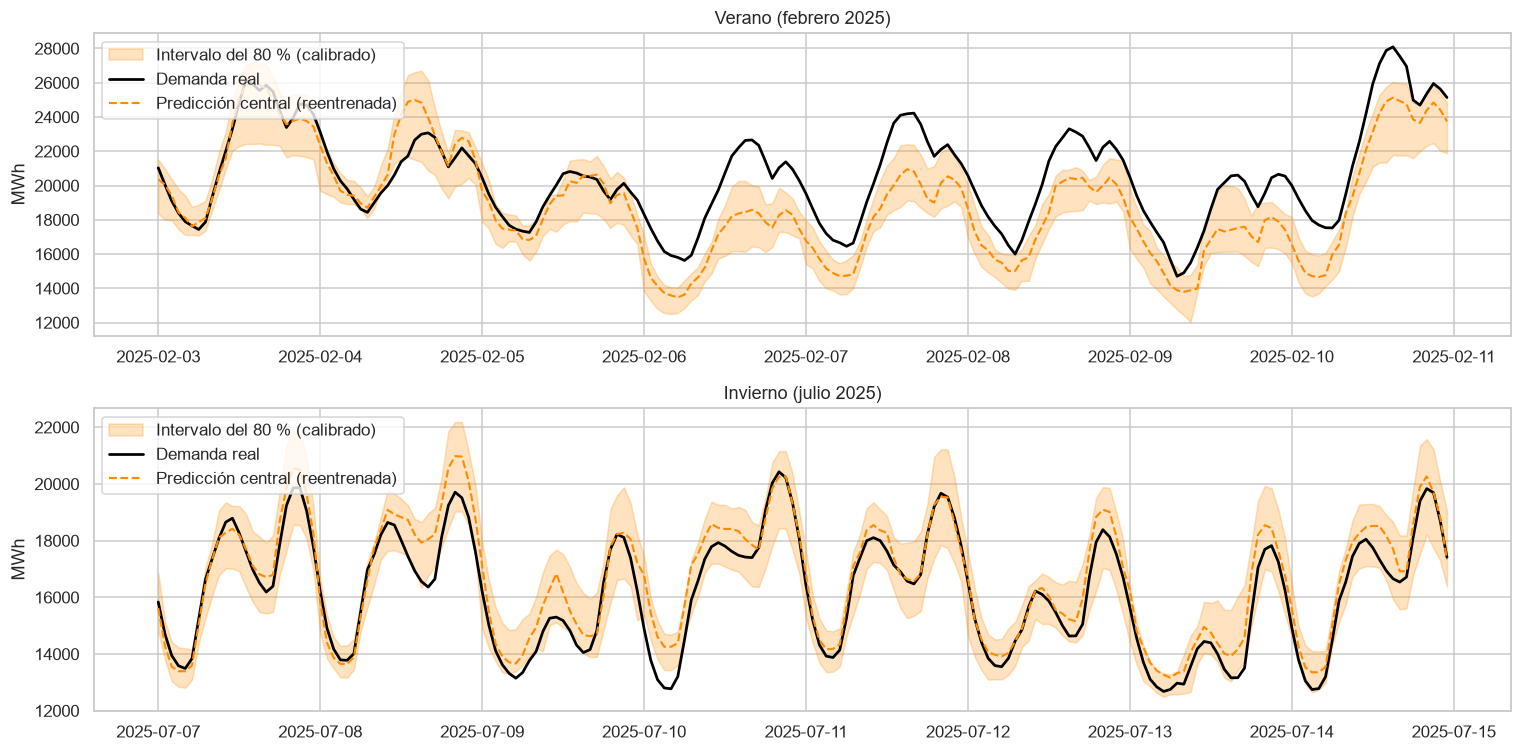

In [33]:
# mismas semanas que en 11.1, ahora con la predicción reentrenada y la banda calibrada.
# Se grafica todo con matplotlib: mezclar fill_between con .plot() de pandas desalinea el eje de fechas.
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
for ax, (titulo, (desde, hasta)) in zip(axes, semanas.items()):
    inferior, superior = q10_cal[desde:hasta], q90_cal[desde:hasta]
    ax.fill_between(inferior.index, inferior.values, superior.values, color="darkorange", alpha=0.25,
                    label="Intervalo del 80 % (calibrado)")
    ax.plot(real[desde:hasta].index, real[desde:hasta].values, lw=1.8, color="black", label="Demanda real")
    ax.plot(pred_reent[desde:hasta].index, pred_reent[desde:hasta].values, lw=1.4, color="darkorange", ls="--",
            label="Predicción central (reentrenada)")
    ax.set(title=titulo, ylabel="MWh")
    ax.legend(loc="upper left")
guardar("intervalo_prediccion")

**Con la calibración conformal la cobertura global llega al 79,3 %** (contra 68,5 % sin calibrar), y las horas que quedan afuera se reparten de forma más pareja: 12,4 % por encima y 8,2 % por debajo. La banda es más ancha (~2.200 MW contra ~1.800 MW), pero el *interval score* mejora (3.184 contra 3.294 MW): el ancho extra se compensa con menos horas afuera.

**Pero el promedio esconde meses en que la banda falla.** La cobertura mensual va del 62 % (febrero de 2025) al 90 % (octubre de 2025), y en 4 de los 19 meses queda por debajo del 75 %: febrero de 2025, noviembre de 2025, enero de 2026 y julio de 2026. En esos meses los errores de muchas horas seguidas van para el mismo lado, y la banda, calibrada con los errores del año anterior, no alcanza: el ajuste es un promedio de 12 meses y no reacciona a un mes particularmente difícil. En los días de calor extremo la cobertura es del 76,6 %.

Se ve en el gráfico: en la semana de febrero de 2025 la demanda real queda **por encima** de la banda varias tardes, y el récord del 10/02 la supera por ~2.000 MW. En la semana de invierno, en cambio, queda dentro casi todo el tiempo.

**Cobertura por hora no es cobertura del día.** Solo en el 31 % de los días las 24 horas quedan dentro de la banda. Una banda del 80 % por hora no promete cubrir el día entero: si el objetivo fuera ese, habría que diseñar una banda distinta (más ancha) para todas las horas a la vez.

**Qué es y qué no es la banda.** Cuantifica la incertidumbre del pronóstico de demanda y puede ser un insumo para estudiar la flexibilidad que necesita el sistema. **No es la reserva necesaria**: la reserva tiene componentes con distintos tiempos de respuesta y también cubre fallas de generación y otros riesgos.

### 11.6 Error según la anticipación

Con un único momento de emisión, cada hora de D se pronostica con distinta **anticipación**: la medianoche, 12 horas después de emitir; las 23 h, 35 horas después. Cuanto más lejos, más se equivoca el pronóstico del tiempo.

Hay una limitación para leer este gráfico: como todas las horas se emiten a la misma hora, **la anticipación y la hora del día van juntas** (anticipación = hora + 12). No se puede separar cuánto del error se debe a la anticipación y cuánto a que algunas horas del día son más difíciles. Se muestra igual el error de temperatura, que sí depende solo de la anticipación.

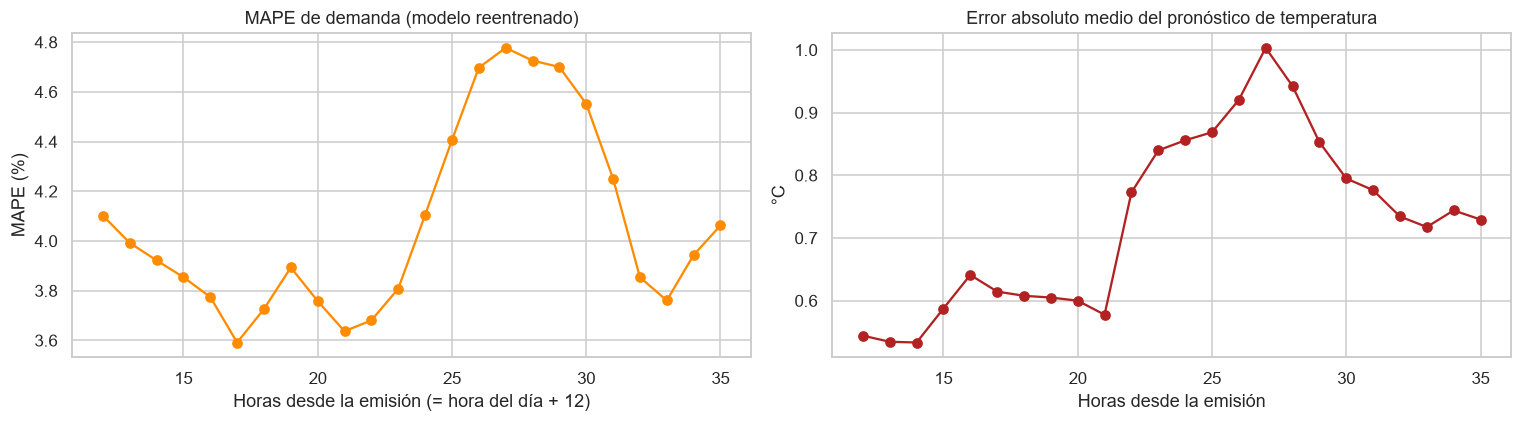

,MAPE_demanda_%,error_temp_°C
12–17 h,3.87,0.58
18–23 h,3.75,0.67
24–29 h,4.57,0.91
30–35 h,4.07,0.75


In [34]:
error_rel_reent = (real - pred_reent).abs() / real * 100
por_anticipacion = pd.DataFrame({
    "MAPE demanda (%)": error_rel_reent.groupby(horizonte).mean(),
    "Error de temperatura (°C)": error_temp.abs().groupby(horizonte).mean(),
})

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
por_anticipacion["MAPE demanda (%)"].plot(ax=axes[0], marker="o", color="darkorange")
axes[0].set(title="MAPE de demanda (modelo reentrenado)", xlabel="Horas desde la emisión (= hora del día + 12)", ylabel="MAPE (%)")
por_anticipacion["Error de temperatura (°C)"].plot(ax=axes[1], marker="o", color="firebrick")
axes[1].set(title="Error absoluto medio del pronóstico de temperatura", xlabel="Horas desde la emisión", ylabel="°C")
guardar("error_por_anticipacion")

# por tramos de anticipación
tramos = pd.cut(horizonte, [11, 17, 23, 29, 35], labels=["12–17 h", "18–23 h", "24–29 h", "30–35 h"])
pd.DataFrame({
    "MAPE_demanda_%": error_rel_reent.groupby(tramos, observed=True).mean(),
    "error_temp_°C": error_temp.abs().groupby(tramos, observed=True).mean(),
}).round(2)

- El error del pronóstico de temperatura crece con la anticipación, pero no de forma pareja: es de ~0,55 °C en las primeras horas y llega a 1 °C hacia las 27 h (las 15 h del día D). Es la hora de máxima temperatura, cuando el pronóstico es más difícil.
- El MAPE de la demanda sigue un patrón parecido: es más alto entre las 24 y las 30 h de anticipación (4,6 %), que corresponden a las **12–17 h** del día D.

Como anticipación y hora del día van juntas, **no se puede atribuir ese aumento a la anticipación**: las tardes son las horas más difíciles para el modelo también con la temperatura observada (sección 11.1). Para separar los dos efectos habría que emitir pronósticos a distintas horas y comparar la misma hora objetivo con distinta anticipación.

### 11.7 ¿Cómo predice los picos?

Que el WAPE y el MAPE sean parecidos **no** alcanza para decir que el modelo acierta en los picos: las dos son métricas promedio de todas las horas. Para el operador lo crítico es el **máximo de cada día** y las horas de demanda alta, así que se miden directamente:

- El error en las **horas de demanda alta** (por encima del percentil 90 de entrenamiento).
- El error en la **magnitud del máximo diario**: cuánto se equivoca el modelo en el valor más alto de cada día.
- La **hora del máximo**: en qué porcentaje de los días el modelo ubica el pico a una hora o menos de la real.
- La **subestimación del máximo**: en cuántos días el modelo se queda corto y cuánto, porque quedarse corto en el pico es el error más caro.

In [35]:
UMBRAL_ALTA = y_train.quantile(0.90)
alta = (real > UMBRAL_ALTA).values

display(pd.DataFrame([
    evaluar("Todas las horas", real, pred_reent),
    evaluar(f"Horas de demanda alta (> {UMBRAL_ALTA:,.0f} MWh)", real[alta], pred_reent[alta]),
]).set_index("modelo"))

# máximo de cada día: magnitud y hora
por_dia = pd.DataFrame({"real": real, "pred": pred_reent})
dias_max = por_dia.groupby(por_dia.index.normalize()).agg(
    max_real=("real", "max"), max_pred=("pred", "max"),
    hora_real=("real", lambda s: s.idxmax().hour), hora_pred=("pred", lambda s: s.idxmax().hour),
)
error_max = (dias_max["max_real"] - dias_max["max_pred"]) / dias_max["max_real"] * 100   # > 0: se queda corto
print(f"Error del máximo diario: MAPE {error_max.abs().mean():.2f} % | sesgo {error_max.mean():+.2f} %")
print(f"Días en que subestima el máximo: {(error_max > 0).mean():.0%} | "
      f"el 10 % de los peores días se queda corto por más de {error_max.quantile(0.90):.1f} %")
print(f"Hora del máximo a 1 hora o menos de la real: {((dias_max['hora_real'] - dias_max['hora_pred']).abs() <= 1).mean():.0%} de los días")

,MAPE_%,WAPE_%,RMSE_MWh,MAE_MWh,sesgo_MWh
modelo,,,,,
Todas las horas,4.07,4.17,930,682,67
"Horas de demanda alta (> 19,579 MWh)",5.55,5.57,1466,1192,532


Error del máximo diario: MAPE 4.09 % | sesgo +1.12 %
Días en que subestima el máximo: 60% | el 10 % de los peores días se queda corto por más de 7.5 %
Hora del máximo a 1 hora o menos de la real: 89% de los días


**Los picos se predicen peor que el promedio**, y eso no se veía en el MAPE ni en el WAPE globales:

- En las **horas de demanda alta** el MAPE es 5,6 %, contra 4,1 % en todas las horas, y el modelo **subestima** (532 MWh en promedio).
- El **máximo de cada día** se predice con un error medio del 4,1 % y un sesgo de +1,1 %: en el 60 % de los días el modelo se queda corto. En el 10 % de los peores días se queda corto por más del 7,5 %.
- La **hora** del máximo sí la ubica bien: en el 89 % de los días, a una hora o menos de la real.

O sea, el modelo sabe **cuándo** va a ser el pico, pero tiende a quedarse corto en **cuánto**. Es coherente con dos limitaciones ya vistas: los árboles no extrapolan por encima de lo que vieron en entrenamiento, y una sola temperatura de Buenos Aires no captura las olas de calor nacionales.

## 12. Clasificación: ¿va a ser una hora pico?

Además de los MWh, al operador le sirve una **alerta**: saber de antemano qué horas van a estar entre las de mayor demanda, para tener lista la generación de reserva.

**Variable objetivo:** `es_pico` = 1 si la demanda de la hora supera el **percentil 90 del período de entrenamiento**. El umbral se calcula solo con train: si se calculara con todo el dataset, el modelo estaría usando información del test.

In [36]:
UMBRAL_PICO = y_train.quantile(0.90)
pico_train = (y_train >= UMBRAL_PICO).astype(int)
pico_test = (y_test >= UMBRAL_PICO).astype(int)

print(f"Umbral de hora pico: {UMBRAL_PICO:,.0f} MWh")
print(f"Horas pico en train: {pico_train.mean():.1%} | en test: {pico_test.mean():.1%}")

Umbral de hora pico: 19,579 MWh
Horas pico en train: 10.0% | en test: 14.9%


Las clases están **desbalanceadas**: solo 1 de cada 10 horas es pico. Esto cambia cómo evaluar:

- La **exactitud** (accuracy) engaña: un modelo que diga siempre "no es pico" acierta el 90 % en train y no sirve para nada.
- Importan la **precisión** (de las alertas que da el modelo, cuántas son picos reales) y sobre todo el **recall** (de los picos reales, cuántos anticipa). Para el operador, un pico no anticipado es más caro que una falsa alarma.
- El **F1** resume precisión y recall en un número, y el **AUC-PR** mide qué tan bien ordena el modelo las horas de más a menos riesgosas.

Por eso los dos modelos se entrenan con `class_weight="balanced"`, que les da más peso a los ejemplos de la clase minoritaria.

Dos aclaraciones sobre el alcance:

- Se usa el umbral de probabilidad estándar (0,5). En la operación, el umbral debería elegirse con los **costos** de cada error (una falsa alarma contra un pico no anticipado); el AUC-PR permite comparar modelos sin fijar ese umbral.
- "Demanda alta" no es lo mismo que "riesgo para el sistema": el riesgo depende también de cuánta generación esté disponible ese día.

### 12.1 Baseline: Regresión Logística

La versión de clasificación de la regresión lineal. Además del one-hot, las variables numéricas se **estandarizan** (media 0, desvío 1), porque la regularización de la regresión logística penaliza más a las variables con números grandes.

In [37]:
preprocesamiento_logistica = ColumnTransformer([
    ("one_hot", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS),
    ("escalado", StandardScaler(), NUMERICAS),
])
modelo_logistica = make_pipeline(
    preprocesamiento_logistica,
    LogisticRegression(class_weight="balanced", max_iter=2000),
)
cv_logistica = cross_val_score(modelo_logistica, X_train, pico_train, cv=cv_temporal, scoring="average_precision")
print(f"Regresión logística | AUC-PR validación cruzada: {cv_logistica.mean():.3f}")
modelo_logistica.fit(X_train, pico_train)

Regresión logística | AUC-PR validación cruzada: 0.724


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['hora','dia_semana','mes',...,'temp_24h','hdd','cdd']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('one_hot', ...), ('escalado', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'

### 12.2 Random Forest clasificador

In [38]:
busqueda_rf_clf = RandomizedSearchCV(
    RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=SEMILLA),
    param_distributions={
        "max_depth": [6, 8, 10, 14, 20, None],
        "min_samples_leaf": [1, 5, 10, 20, 40],
        "max_features": [0.5, 0.7, 1.0],
    },
    n_iter=15, cv=cv_temporal, scoring="average_precision",
    random_state=SEMILLA, n_jobs=1,
)
busqueda_rf_clf.fit(X_train, pico_train)
print("Mejores hiperparámetros:", busqueda_rf_clf.best_params_)
print(f"AUC-PR validación cruzada: {busqueda_rf_clf.best_score_:.3f}")

Mejores hiperparámetros: {'min_samples_leaf': 40, 'max_features': 0.7, 'max_depth': 10}
AUC-PR validación cruzada: 0.804


### 12.3 Evaluación en test

In [39]:
clasificadores = {"Regresión logística": modelo_logistica, "Random Forest": busqueda_rf_clf.best_estimator_}
filas = []
for nombre, modelo in clasificadores.items():
    # escenario real: temperatura pronosticada
    prob = modelo.predict_proba(X_test_pron)[:, 1]
    pred = (prob >= 0.5).astype(int)
    filas.append({
        "modelo": nombre,
        "precisión": precision_score(pico_test, pred),
        "recall": recall_score(pico_test, pred),
        "F1": f1_score(pico_test, pred),
        "AUC-ROC": roc_auc_score(pico_test, prob),
        "AUC-PR": average_precision_score(pico_test, prob),
        # comparación: AUC-PR con la temperatura observada
        "AUC-PR_temp_obs": average_precision_score(pico_test, modelo.predict_proba(X_test)[:, 1]),
    })
tabla_clf = pd.DataFrame(filas).set_index("modelo").round(3)
tabla_clf

,precisión,recall,F1,AUC-ROC,AUC-PR,AUC-PR_temp_obs
modelo,,,,,,
Regresión logística,0.577,0.911,0.706,0.961,0.801,0.811
Random Forest,0.622,0.915,0.741,0.970,0.870,0.882


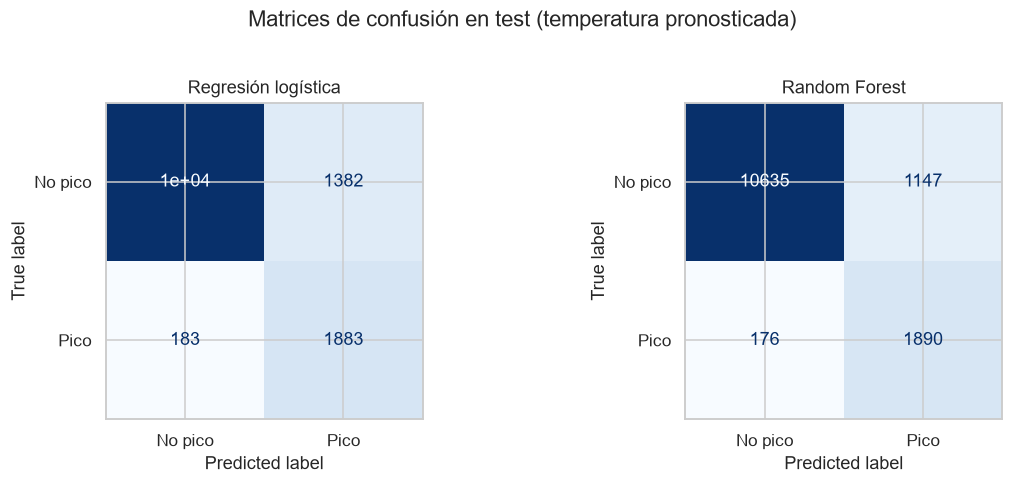

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, (nombre, modelo) in zip(axes, clasificadores.items()):
    ConfusionMatrixDisplay.from_estimator(
        modelo, X_test_pron, pico_test, display_labels=["No pico", "Pico"], cmap="Blues", ax=ax, colorbar=False,
    )
    ax.set_title(nombre)
fig.suptitle("Matrices de confusión en test (temperatura pronosticada)", y=1.02)
guardar("matrices_confusion")

In [41]:
mejor_clf = tabla_clf["AUC-PR"].idxmax()
print(f"Reporte del mejor clasificador ({mejor_clf}):\n")
print(classification_report(pico_test, clasificadores[mejor_clf].predict(X_test_pron), target_names=["No pico", "Pico"]))

Reporte del mejor clasificador (Random Forest):

              precision    recall  f1-score   support

     No pico       0.98      0.90      0.94     11782
        Pico       0.62      0.91      0.74      2066

    accuracy                           0.90     13848
   macro avg       0.80      0.91      0.84     13848
weighted avg       0.93      0.90      0.91     13848



Lectura:

- El Random Forest **anticipa el 91,5 % de las horas de demanda alta** (recall) y le gana en todas las métricas a la regresión logística.
- De sus alertas, el 62 % son horas de demanda alta reales (precisión). Las falsas alarmas son el costo de priorizar el recall.
- Con la temperatura observada el AUC-PR sería 0,882 en vez de 0,870: igual que en la regresión, el pronóstico del tiempo casi no cambia el resultado.
- Que en el test haya 14,9 % de horas de demanda alta, contra el 10 % de train, es otra consecuencia del cambio de nivel de la demanda: con el mismo umbral, cada año hay más horas que lo superan.

## 13. Variante predictiva: con demanda reciente

El modelo principal no usa demanda pasada, por decisión de diseño: explica la demanda solo con calendario y clima. Pero si el objetivo es **solo predecir**, conviene medir cuánto aporta la demanda reciente, que trae el nivel actual del sistema (incluido el crecimiento que el modelo no conoce).

**Qué rezagos se pueden usar.** Hay que respetar lo que se conoce al emitir (D-1 12:00): la última hora medida es D-1 11:00. Para la hora 23 de D, eso es 36 horas antes. Por eso:

- **Hace 24 h** no sirve: para las horas de la tarde y noche de D, la demanda de 24 h antes todavía no ocurrió al emitir.
- **Hace 48 h** (misma hora de anteayer) y **hace 168 h** (misma hora de la semana anterior) sí están disponibles para todas las horas.

Se supone acceso a la medición en tiempo real de la demanda.

**Cómo se elige.** Se comparan cuatro variantes con la misma **validación cruzada temporal** de las secciones anteriores, solo dentro de train, y con los mismos hiperparámetros del Gradient Boosting (no se vuelven a optimizar). Para comparar sobre las mismas filas, se descarta la primera semana de 2021, que no tiene demanda de 168 h antes.

**Advertencia.** Una revisión externa ya había probado estos rezagos sobre el mismo período de test. Aunque acá la variante se **elige** solo con train, el test ya no es un período "nuevo" para esta comparación: el resultado es indicativo, no una validación independiente. Para confirmarlo habría que evaluarlo en meses posteriores a julio de 2026.

In [42]:
for k in (48, 168):
    df[f"demanda_hace_{k}h"] = df["demanda_mwh"].shift(k)

variantes = {
    "Sin rezagos (modelo explicativo)": [],
    "Hace 168 h": ["demanda_hace_168h"],
    "Hace 48 h": ["demanda_hace_48h"],
    "Hace 48 h y 168 h": ["demanda_hace_48h", "demanda_hace_168h"],
}
con_historia = en_train & df["demanda_hace_168h"].notna()

filas = []
for nombre, extra in variantes.items():
    cv = -cross_val_score(
        HistGradientBoostingRegressor(**PARAMS_GB),
        df.loc[con_historia, VARIABLES + extra], df.loc[con_historia, "demanda_mwh"],
        cv=cv_temporal, scoring="neg_mean_absolute_percentage_error",
    )
    filas.append({"variante": nombre, "MAPE_validacion_%": cv.mean() * 100, "desvio_entre_folds": cv.std() * 100})
validacion_rezagos = pd.DataFrame(filas).set_index("variante").round(2)
VARIANTE = validacion_rezagos["MAPE_validacion_%"].idxmin()
print(f"Variante elegida en validación: {VARIANTE}")
validacion_rezagos

Variante elegida en validación: Hace 48 h y 168 h


,MAPE_validacion_%,desvio_entre_folds
variante,,
Sin rezagos (modelo explicativo),4.51,0.48
Hace 168 h,4.45,0.47
Hace 48 h,4.14,0.55
Hace 48 h y 168 h,4.10,0.52


In [43]:
# evaluación en test (temperatura disponible al emitir), modelo fijo entrenado con 2021–2024
REZAGOS = variantes[VARIANTE]
modelo_rezagos = HistGradientBoostingRegressor(**PARAMS_GB).fit(
    df.loc[con_historia, VARIABLES + REZAGOS], df.loc[con_historia, "demanda_mwh"])
X_test_rezagos = X_test_pron.join(df.loc[~en_train, REZAGOS])
pred_rezagos = pd.Series(modelo_rezagos.predict(X_test_rezagos[VARIABLES + REZAGOS]), index=t_test.values)

comparacion = pd.DataFrame([
    evaluar("Explicativo, fijo", real, predicciones["Gradient Boosting"]),
    evaluar(f"Explicativo, reentrenado cada mes ({NOMBRE_VENTANA.lower()})", real, pred_reent),
    evaluar(f"Con rezagos ({VARIANTE.lower()}), fijo", real, pred_rezagos),
]).set_index("modelo")
comparacion["MAPE_horas_alta_%"] = [
    mean_absolute_percentage_error(real[alta], np.asarray(p)[alta]) * 100
    for p in (predicciones["Gradient Boosting"], pred_reent, pred_rezagos)
]
comparacion.round(2)

,MAPE_%,WAPE_%,RMSE_MWh,MAE_MWh,sesgo_MWh,MAPE_horas_alta_%
modelo,,,,,,
"Explicativo, fijo",4.07,4.21,961,688,234,5.68
"Explicativo, reentrenado cada mes (últimos 24 meses)",4.07,4.17,930,682,67,5.55
"Con rezagos (hace 48 h y 168 h), fijo",3.61,3.71,872,607,124,4.94


**La demanda reciente mejora el pronóstico de forma clara:**

- En la **validación temporal** (solo train), la variante con demanda de hace 48 h y 168 h baja el MAPE de 4,51 % a 4,10 %. La de 48 h sola aporta casi todo (4,14 %): la demanda de anteayer a la misma hora trae el nivel reciente del sistema. La de 168 h sola aporta poco (4,45 %).
- En el **test**, la variante elegida tiene MAPE 3,61 % contra 4,07 % del modelo explicativo, y mejora también en las horas de demanda alta (4,9 % contra 5,6–5,7 %). Reduce el sesgo menos que el reentrenamiento mensual (124 contra 67 MWh), pero baja mucho más el error total.

**Cómo leerlo:**

- Es un modelo para **predecir**, no para explicar. El modelo principal sigue siendo el explicativo: cuenta cómo el calendario y el clima mueven la demanda. Esta variante dice cuánto se gana si además se le da el nivel reciente.
- Depende de que la demanda esté disponible en tiempo real al emitir. Si solo se contara con la planilla mensual de CAMMESA, no se podría usar.
- Como se advirtió arriba, el test ya había sido usado para explorar estos rezagos. La **elección** se hizo correctamente con validación en train, y el test la confirma, pero no es una prueba independiente.

## 14. Conclusiones

**Regresión: predecir los MWh de cada hora** (test con la temperatura que se conocía al emitir, D-1 12:00)

| Modelo | MAPE validación | MAPE test | WAPE test |
|---|---|---|---|
| Referencia: misma hora semana anterior | — | 9,1 % | 9,2 % |
| Referencia: perfil promedio | — | 7,6 % | 7,9 % |
| Regresión lineal | 6,3 % | 6,1 % | 6,2 % |
| Random Forest | 4,8 % | 4,3 % | 4,4 % |
| **Gradient Boosting (modelo explicativo elegido)** | **4,5 %** | **4,1 %** | **4,2 %** |
| Gradient Boosting reentrenado cada mes (últimos 24 meses) | — | 4,1 % | 4,2 % |
| Variante predictiva: + demanda de hace 48 h y 168 h | 4,1 % | 3,6 % | 3,7 % |

- **Modelo elegido: Gradient Boosting**, por tener el menor error en validación cruzada temporal. Con la temperatura que se conocería al emitir el pronóstico se equivoca en promedio un **4,1 %**, menos de la mitad que la referencia "misma hora de la semana anterior" (9,1 %), usando solo calendario y temperatura.
- **El error del pronóstico del tiempo cuesta poco:** con la temperatura observada el error sería 3,98 %. La diferencia es de 0,09 puntos.
- Los modelos de árboles le ganan a la regresión lineal porque capturan la interacción hora × estación sin construirla a mano.
- **Overfitting controlado:** la curva de validación muestra dónde el error de validación deja de mejorar, y la búsqueda de hiperparámetros, con validación cruzada temporal y sin *early stopping* al azar, eligió configuraciones regularizadas. El Gradient Boosting tiene la menor brecha entre train y test (3,4 % contra 4,0 % con temperatura observada).

**Lo que muestran los análisis de la pre-entrega 4 y la revisión final**

- **Picos:** el modelo ubica bien la hora del máximo diario (89 % de los días a ±1 h), pero tiende a quedarse corto en su magnitud. En las horas de demanda alta el MAPE es 5,6 %.
- **Días de calor extremo:** el error es un 25 % mayor y no tiene sesgo claro: son días más inciertos.
- **Reentrenamiento mensual:** reduce el sesgo (234 → 67 MWh) pero no el error total.
- **Intervalos del 80 %:** calibrados, cubren el 79,3 % de las horas en promedio, pero menos del 75 % en 4 de 19 meses. Cuantifican la incertidumbre de la demanda; no son la reserva del sistema.
- **Demanda reciente:** agregar la demanda de hace 48 y 168 horas, que está disponible al emitir, baja el MAPE a 3,6 %. Es la mejora más grande, pero cambia el tipo de modelo: de explicativo a predictivo.

**Clasificación: anticipar horas de demanda alta**

- El Random Forest clasificador anticipa el **91,5 %** de las horas de demanda alta con una precisión del 62 % (AUC-PR 0,870). El umbral de alerta debería elegirse con los costos reales de cada error.

**Limitaciones**

- **Supuestos de operación:** la emisión a las 12:00 del día anterior y la disponibilidad de la demanda en tiempo real son supuestos razonables, no el procedimiento oficial de CAMMESA.
- **Nivel de la demanda:** el modelo explicativo no lo conoce. El reentrenamiento lo corrige con retraso, y la causa de la subestimación de 2026 no está del todo identificada: la demanda comparable creció solo 0,9 %.
- **Una sola ciudad:** la temperatura de Buenos Aires no captura bien las olas de calor nacionales. Por eso el mayor error está en las tardes de verano.
- **Calendario binario:** hábil / no hábil no distingue vísperas, puentes ni vacaciones de verano. El notebook 03 muestra que los días hábiles de enero se comportan como fines de semana.
- **Test reutilizado:** los cambios de esta revisión se evaluaron sobre el mismo período de test. Para una validación independiente haría falta evaluar en meses posteriores a julio de 2026.